# Expected Credit Loss and User Risk Premium: integrated results on the Aave v3 valuation cohorts

## 0. Purpose and assumptions

**Purpose.** The tutor asked for one table per scenario $\times$ profile that follows the whole actuarial chain, step by step, *before* the User Risk Premium (URP) is calibrated, so that the economic sense of the numbers can be judged:

$$\text{number of wallets} \;\to\; \text{initial distribution by state} \;\to\; \mathbf{P} \;\to\; \mathbf{P}^{30} \;\to\; \text{PD by state} \;\to\; \text{LGD} \;\to\; \text{ECL}.$$

The notebook has two parts.

- **Part 1 (Sections 1-5): the PD side.** It loads the exports of notebooks 02 and 03, validates them, describes the valuation cohort (the wallets observed at $t$), shows the daily $\mathbf{P}$ with the depth of every cell, the 30-day $\mathbf{P}^{30}$ and the PD by state with its bootstrap interval, and runs the **in-sample backtest** on the day-1 cohort.
- **Part 2 (Sections 6-10): EXPLORATORY LGD and ECL variants.** This is a *menu for discussion with the tutor*, **not the final LGD**. Every variant uses the same PD; they differ only in how the loss given a liquidation event is measured. The variants are exported to `data/02_interim/ecl_variants_not_for_prod.csv`.

**Assumptions (all inherited from `docs/decisions.md`; none is re-litigated here).**

1. **Horizon $K = 30$ days.** $\mathrm{PD}_i = [\mathbf{P}^{30}]_{i,S7}$ is the probability that a wallet that starts in state $i$ at $t$ reaches a liquidation event within the next 30 days.
2. **`S1` (observed repayment) and `S7` (liquidation event) are absorbing.** `S7` is a *technical* default, not an economic one: the matrix estimates the probability of the event, and the LGD says whether the event costs the protocol anything. That keeps $\text{EAD} \times \text{PD} \times \text{LGD}$ coherent.
3. **Calibration window $[t-30, t]$.** $\mathbf{N}$, $\mathbf{P}$ and $\mathbf{P}^{30}$ come from notebook 02 (the `n_S*` columns of `markov_segment_params_not_for_prod.csv`); the EVT shocks come from notebook 03. **No datum of the out-of-time window $(t, t+30]$ is used in this notebook**: the `oot_*` columns of the cohort file are ignored on purpose (they belong to the out-of-time backtest).
4. **Base panel:** users-days with total debt $\ge$ USD 100 (`min_debt_usd = 100`).
5. **Profiles:** A ($\ge 85\%$ ETH/LST collateral) and B ($\ge 85\%$ UNI + LINK), stablecoin debt only.
6. **Valuation cohort** = wallets observed at $t$ (EAD = their total debt at $t$). **In-sample backtest cohort** = wallets observed on day $t-30$, without late entrants.
7. **LGD side (Part 2):** shocks are per asset, weighted by each wallet's collateral composition, with **comonotonic** dependence (all assets fall at once by their own expected shortfall); stablecoin collateral is not shocked (parity), LSTs take the ETH shock; the LGD is conditional on the liquidation event and is a 1-day quantity (the 30-day path to the trigger is already inside the PD).

## 1. Load and validate the inputs

Four files from `data/02_interim/` are read (the older `notebook_export_*` Markov files are not used):

- `markov_segment_params_not_for_prod.csv` (notebook 02, Section 18): per scenario $\times$ profile $\times$ origin state, the counts $n_{S1..S7}$, the full row of $\mathbf{P}^{30}$, the 30-day PD with its wallet-bootstrap interval, and the row depth. Only the base rows (`min_debt_usd = 100`) are used for the main tables.
- `markov_wallet_cohorts_not_for_prod.csv` (notebook 02, Section 18): one row per wallet and cohort.
- `evt_shock_grid_not_for_prod.csv`, `evt_breakeven_not_for_prod.csv` and `notebook_export_evt_shocks_not_for_prod.csv` (notebook 03): ES price shocks by asset, level and horizon; break-even shocks with the Aave LT/LB; the ES 99% base shocks.

**Validation.** From the counts the daily matrix is rebuilt: each transient row is normalised by its sum, the rows of `S1` and `S7` are the identity (absorbing by definition), and a transient row without observed transitions is also the identity (it cannot be estimated). Then $\mathbf{P}^{30}$ is recomputed and compared with the exported `p30_*` columns (absolute tolerance $10^{-10}$), and the PD (column `S7`) with `pd30_point`. For an empty row the export leaves `p30_*` and `pd30_*` empty; the rebuilt identity row gives PD $= 0$, which is **not an estimate**: the cell is flagged and the point PD is used as 0 with a degenerate interval.

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

sys.path.append(os.path.abspath(".."))

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update(
    {
        "figure.figsize": (10, 5),
        "axes.titlesize": 12,
        "axes.labelsize": 11,
        "legend.frameon": True,
        "axes.spines.top": False,
    }
)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)

INTERIM_DATA_DIR = Path(os.environ.get("ECL_INTERIM_DATA_DIR", "../data/02_interim"))
SEGMENT_PARAMS_PATH = INTERIM_DATA_DIR / "markov_segment_params_not_for_prod.csv"
COHORTS_PATH = INTERIM_DATA_DIR / "markov_wallet_cohorts_not_for_prod.csv"
SHOCK_GRID_PATH = INTERIM_DATA_DIR / "evt_shock_grid_not_for_prod.csv"
BREAKEVEN_PATH = INTERIM_DATA_DIR / "evt_breakeven_not_for_prod.csv"
BASE_SHOCKS_PATH = INTERIM_DATA_DIR / "notebook_export_evt_shocks_not_for_prod.csv"
ECL_EXPORT_PATH = INTERIM_DATA_DIR / "ecl_variants_not_for_prod.csv"

SCENARIOS = ["baseline_mar2024", "stress_aug2024"]
PROFILES = ["A", "B"]
SEGMENTS = [(scenario, profile) for scenario in SCENARIOS for profile in PROFILES]
VALUATION_DATE = {"baseline_mar2024": "2024-03-15", "stress_aug2024": "2024-08-05"}
DAY1_DATE = {"baseline_mar2024": "2024-02-14", "stress_aug2024": "2024-07-06"}

STATE_ORDER = [f"S{i}" for i in range(1, 8)]
TRANSIENT_STATES = STATE_ORDER[1:6]  # S2..S6
ABSORBING_STATES = ["S1", "S7"]
STATE_INDEX = {state: idx for idx, state in enumerate(STATE_ORDER)}
N_STATES = len(STATE_ORDER)
S1_IDX, S7_IDX = STATE_INDEX["S1"], STATE_INDEX["S7"]
ABSORBING_IDX = [STATE_INDEX[state] for state in ABSORBING_STATES]

HORIZON_DAYS = 30
BASE_MIN_DEBT_USD = 100.0
STOCHASTIC_TOLERANCE = 1e-9
P30_TOLERANCE = 1e-10
MIN_ROW_DEPTH = 30  # same threshold as notebook 02 (thin origin states)
MIN_S7_EVENTS = 5  # an origin state with fewer observed S7 transitions is flagged


def segment_name(segment: tuple[str, str]) -> str:
    """Short label of a (scenario, profile) segment, e.g. ``baseline | A``."""
    return f"{segment[0].split('_')[0]} | {segment[1]}"


SEGMENT_LABELS = [segment_name(segment) for segment in SEGMENTS]

REQUIRED_SEGMENT_COLUMNS = (
    ["scenario", "profile", "current_state"]
    + [f"n_{state}" for state in STATE_ORDER]
    + [f"p30_{state}" for state in STATE_ORDER]
    + ["pd30_point", "pd30_ci_low", "pd30_ci_high", "min_debt_usd", "row_depth", "row_empty"]
)
REQUIRED_COHORT_COLUMNS = [
    "scenario", "profile", "user_id", "cohort", "date", "state", "health_factor", "total_debt_usd",
    "total_collateral_usd", "eth_core_usd", "wbtc_usd", "uni_usd", "link_usd", "stable_usd", "lt_w", "lb_w",
    "is_late_entrant", "final_state", "event_date", "exit_reason", "s7_trigger", "hf_at_s7_entry",
    "hf_at_s7_entry_prev_day", "days_s7_to_liquidation", "oot_outcome", "oot_event_date",
]  # fmt: skip


def daily_matrix_from_counts(counts: np.ndarray) -> np.ndarray:
    """Row-stochastic daily matrix from a (K, K) count matrix.

    Each transient row is normalised by its sum. The rows of S1 and S7 (absorbing by definition) and the
    transient rows without any observed transition (not estimable) are identity rows.
    """
    totals = counts.sum(axis=1, keepdims=True)
    safe_totals = np.where(totals > 0, totals, 1.0)
    daily = np.where(totals > 0, counts / safe_totals, np.eye(N_STATES))
    for idx in ABSORBING_IDX:
        daily[idx, :] = 0.0
        daily[idx, idx] = 1.0
    return daily


def load_markov_segments(params: pd.DataFrame) -> dict[tuple[str, str], dict]:
    """Rebuild N, daily P, P^30 and the PD table of every segment, checking them against the export."""
    segments: dict[tuple[str, str], dict] = {}
    for segment in SEGMENTS:
        block = params.loc[(params["scenario"] == segment[0]) & (params["profile"] == segment[1])]
        assert len(block) == N_STATES and block["current_state"].is_unique, f"{segment}: expected one row per state."
        block = block.set_index("current_state").loc[STATE_ORDER]

        counts = block[[f"n_{state}" for state in STATE_ORDER]].to_numpy(dtype=float)
        assert np.isfinite(counts).all() and (counts >= 0).all(), f"{segment}: invalid counts."
        assert counts[ABSORBING_IDX].sum() == 0, f"{segment}: counts on an absorbing row."
        row_depth = counts.sum(axis=1)
        assert np.array_equal(row_depth, block["row_depth"].to_numpy(dtype=float)), f"{segment}: row_depth mismatch."
        row_empty = pd.Series((row_depth == 0) & np.isin(STATE_ORDER, TRANSIENT_STATES), index=STATE_ORDER)
        assert np.array_equal(row_empty.to_numpy(), block["row_empty"].astype(bool).to_numpy()), f"{segment}: row_empty mismatch."

        daily = daily_matrix_from_counts(counts)
        assert np.allclose(daily.sum(axis=1), 1.0, atol=STOCHASTIC_TOLERANCE), f"{segment}: rows of P do not sum to 1."
        assert (daily >= 0).all()
        horizon = np.linalg.matrix_power(daily, HORIZON_DAYS)
        assert np.allclose(horizon.sum(axis=1), 1.0, atol=STOCHASTIC_TOLERANCE), f"{segment}: rows of P^30 do not sum to 1."

        exported = block[[f"p30_{state}" for state in STATE_ORDER]].to_numpy(dtype=float)
        estimated = ~row_empty.to_numpy()
        assert np.isfinite(exported[estimated]).all(), f"{segment}: missing p30 on an estimated row."
        assert np.isnan(exported[~estimated]).all(), f"{segment}: p30 present on an empty row."
        gap_p30 = float(np.abs(exported[estimated] - horizon[estimated]).max())
        assert gap_p30 <= P30_TOLERANCE, f"{segment}: P^30 differs from the export by {gap_p30:.2e}."

        pd_point = block["pd30_point"].to_numpy(dtype=float)
        gap_pd = float(np.abs(pd_point[estimated] - horizon[estimated, S7_IDX]).max())
        assert gap_pd <= P30_TOLERANCE, f"{segment}: PD differs from column S7 of P^30 by {gap_pd:.2e}."
        ci_low = block["pd30_ci_low"].to_numpy(dtype=float)
        ci_high = block["pd30_ci_high"].to_numpy(dtype=float)
        assert np.isfinite(ci_low[estimated]).all() and np.isfinite(ci_high[estimated]).all()
        assert (pd_point[estimated] >= -STOCHASTIC_TOLERANCE).all() and (pd_point[estimated] <= 1 + STOCHASTIC_TOLERANCE).all()
        assert (ci_low[estimated] <= pd_point[estimated] + 1e-12).all(), f"{segment}: CI low above the point estimate."
        assert (pd_point[estimated] <= ci_high[estimated] + 1e-12).all(), f"{segment}: CI high below the point estimate."

        pd_table = pd.DataFrame(
            {
                "pd30": horizon[:, S7_IDX],  # empty rows: identity row -> 0 (not an estimate)
                "ci_low": np.where(estimated, ci_low, 0.0),
                "ci_high": np.where(estimated, ci_high, 0.0),
                "estimated": estimated,
                "row_depth": row_depth.astype(int),
                "n_to_S7": counts[:, S7_IDX].astype(int),
            },
            index=pd.Index(STATE_ORDER, name="current_state"),
        )
        segments[segment] = {
            "N": pd.DataFrame(counts.astype(int), index=STATE_ORDER, columns=STATE_ORDER),
            "P": pd.DataFrame(daily, index=STATE_ORDER, columns=STATE_ORDER),
            "P30": pd.DataFrame(horizon, index=STATE_ORDER, columns=STATE_ORDER),
            "pd": pd_table,
            "row_empty": row_empty,
            "gap_p30": gap_p30,
            "gap_pd": gap_pd,
        }
    return segments


segment_params_all = pd.read_csv(SEGMENT_PARAMS_PATH)
cohorts_all = pd.read_csv(COHORTS_PATH)
shock_grid = pd.read_csv(SHOCK_GRID_PATH)
breakeven = pd.read_csv(BREAKEVEN_PATH)
base_shocks = pd.read_csv(BASE_SHOCKS_PATH)

assert set(REQUIRED_SEGMENT_COLUMNS) <= set(segment_params_all.columns), "Segment export lacks required columns."
assert set(REQUIRED_COHORT_COLUMNS) <= set(cohorts_all.columns), "Cohort export lacks required columns."

min_debt_levels = [float(level) for level in sorted(segment_params_all["min_debt_usd"].unique())]
segment_params = segment_params_all.loc[np.isclose(segment_params_all["min_debt_usd"], BASE_MIN_DEBT_USD)]
print(f"min_debt_usd levels in the segment export: {min_debt_levels} -> base rows used: {len(segment_params)}")
print(f"rows with another minimum debt (sensitivity, not used here): {len(segment_params_all) - len(segment_params)}")
print(f"wallet cohorts: {len(cohorts_all):,} rows; cohorts = {sorted(cohorts_all['cohort'].unique())}")

markov = load_markov_segments(segment_params)

validation_rows = []
for segment, entry in markov.items():
    validation_rows.append(
        {
            "segment": segment_name(segment),
            "min |row sum - 1| (P)": float(np.abs(entry["P"].sum(axis=1) - 1).max()),
            "max |P^30 - export|": entry["gap_p30"],
            "max |PD - pd30_point|": entry["gap_pd"],
            "empty transient rows": ", ".join(entry["row_empty"].index[entry["row_empty"]]) or "-",
        }
    )
display(pd.DataFrame(validation_rows).set_index("segment"))
print("All input assertions passed (rows stochastic, P^30 equals the export within 1e-10, PD equals column S7).")
for segment, entry in markov.items():
    if entry["row_empty"].any():
        empties = list(entry["row_empty"].index[entry["row_empty"]])
        print(f"WARNING {segment_name(segment)}: origin state(s) {empties} have no observed transition; their PD is a placeholder 0, not an estimate.")

min_debt_usd levels in the segment export: [100.0] -> base rows used: 28
rows with another minimum debt (sensitivity, not used here): 0
wallet cohorts: 14,142 rows; cohorts = ['day1', 'valuation']


,min |row sum - 1| (P),max |P^30 - export|,max |PD - pd30_point|,empty transient rows
segment,,,,
baseline | A,2.220446e-16,8.673617e-17,8.673617e-17,-
baseline | B,0.000000e+00,8.326673e-17,0.000000e+00,S6
stress | A,2.220446e-16,9.367507e-17,6.938894e-17,-
stress | B,1.110223e-16,9.887924e-17,5.551115e-17,-


All input assertions passed (rows stochastic, P^30 equals the export within 1e-10, PD equals column S7).
WARNING baseline | B: origin state(s) ['S6'] have no observed transition; their PD is a placeholder 0, not an estimate.


## 2. Valuation cohort: wallets observed at $t$

The valuation cohort is the portfolio the premium has to price: every wallet with debt in the panel on the valuation date ($t$ = 2024-03-15 for the baseline and 2024-08-05 for the stress scenario). The **state** is the one observed that day (HF bands: `S2` $HF \ge 2$, `S3` $1.5 \le HF < 2$, `S4` $1.25 \le HF < 1.5$, `S5` $1.10 \le HF < 1.25$, `S6` $1 < HF < 1.10$), and **EAD is the total debt in USD at $t$**.

Wallets already in `S7` at $t$ (HF $\le 1$ or a liquidation call in the last interval) are **already inside a liquidation event at valuation**: they are not part of the forward-looking risk of the chain (their PD is 1 by definition) and are reported on a separate line. `late` counts the wallets that were not in the panel on day $t-30$ (late entrants and re-entries); they belong to the valuation cohort but not to the in-sample backtest.


baseline_mar2024 | profile A  (valuation date 2024-03-15)


,n,% wallets,EAD (USD),% EAD,late entrants,median HF
line,,,,,,
S2,2055,76.7,"442,972,597",49.2,313,3.29
S3,403,15.0,"228,210,708",25.3,157,1.79
S4,153,5.7,"134,562,252",14.9,64,1.40
S5,61,2.3,"94,390,266",10.5,20,1.18
S6,5,0.2,"651,511",0.1,1,1.04
S2-S6 (at risk),2677,99.9,"900,787,334",100.0,555,2.90
S7 at valuation (already in a liquidation event),4,0.1,"24,349",0.0,1,1.05
Total,2681,100.0,"900,811,683",100.0,556,2.89



baseline_mar2024 | profile B  (valuation date 2024-03-15)


,n,% wallets,EAD (USD),% EAD,late entrants,median HF
line,,,,,,
S2,219,72.8,"15,335,560",63.4,42,3.17
S3,56,18.6,"6,262,465",25.9,19,1.75
S4,21,7.0,"1,790,158",7.4,8,1.35
S5,4,1.3,"781,450",3.2,0,1.23
S6,0,0.0,0,0.0,0,nan
S2-S6 (at risk),300,99.7,"24,169,633",100.0,69,2.64
S7 at valuation (already in a liquidation event),1,0.3,946,0.0,0,0.69
Total,301,100.0,"24,170,579",100.0,69,2.64



stress_aug2024 | profile A  (valuation date 2024-08-05)


,n,% wallets,EAD (USD),% EAD,late entrants,median HF
line,,,,,,
S2,1314,32.9,"224,086,233",18.3,224,2.75
S3,997,25.0,"349,709,679",28.6,195,1.71
S4,817,20.5,"340,849,717",27.9,173,1.37
S5,484,12.1,"166,402,207",13.6,89,1.18
S6,245,6.1,"132,294,411",10.8,44,1.06
S2-S6 (at risk),3857,96.6,"1,213,342,247",99.3,725,1.65
S7 at valuation (already in a liquidation event),135,3.4,"8,771,790",0.7,22,1.08
Total,3992,100.0,"1,222,114,038",100.0,747,1.62



stress_aug2024 | profile B  (valuation date 2024-08-05)


,n,% wallets,EAD (USD),% EAD,late entrants,median HF
line,,,,,,
S2,109,29.9,"6,980,453",24.2,17,2.53
S3,94,25.8,"4,862,023",16.9,15,1.72
S4,75,20.6,"4,733,939",16.4,15,1.38
S5,55,15.1,"9,736,894",33.8,3,1.18
S6,20,5.5,"1,737,072",6.0,3,1.04
S2-S6 (at risk),353,97.0,"28,050,381",97.3,53,1.61
S7 at valuation (already in a liquidation event),11,3.0,"787,868",2.7,1,1.26
Total,364,100.0,"28,838,249",100.0,54,1.60



Valuation cohort size (wallets with debt at t):


n wallets      EAD (USD)
scenario         profile                          
baseline_mar2024 A             2681    900,811,683
                 B              301     24,170,579
stress_aug2024   A             3992  1,222,114,038
                 B              364     28,838,249

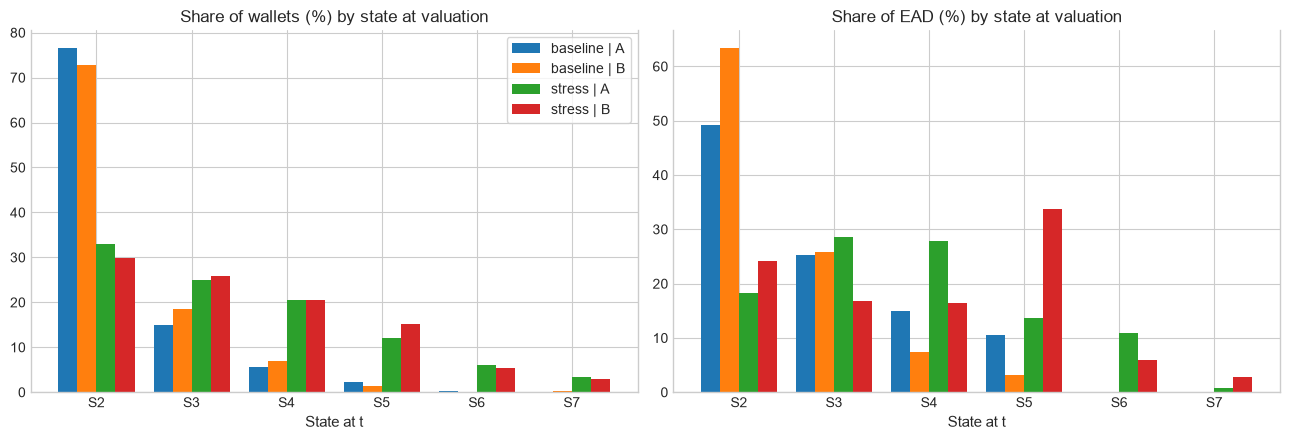

In [2]:
valuation = cohorts_all.loc[cohorts_all["cohort"] == "valuation"].copy().reset_index(drop=True)
COLLATERAL_GROUPS = ["eth_core_usd", "wbtc_usd", "uni_usd", "link_usd", "stable_usd"]

assert valuation["state"].isin(TRANSIENT_STATES + ["S7"]).all(), "Valuation cohort has a state outside S2-S7."
assert not valuation.duplicated(["scenario", "user_id"]).any(), "A wallet appears twice in a scenario."
for scenario in SCENARIOS:
    assert set(valuation.loc[valuation["scenario"] == scenario, "date"]) == {VALUATION_DATE[scenario]}, "Unexpected valuation date."
assert np.isfinite(valuation[["health_factor", "total_debt_usd", "total_collateral_usd", "lt_w", "lb_w"]]).all().all()
assert (valuation["total_debt_usd"] > 0).all() and (valuation["total_collateral_usd"] > 0).all()
assert (valuation["total_debt_usd"] >= BASE_MIN_DEBT_USD - 1e-6).all(), "A valuation wallet is below the minimum debt of the panel."
assert np.allclose(valuation[COLLATERAL_GROUPS].sum(axis=1), valuation["total_collateral_usd"], rtol=1e-9, atol=1e-6)
assert (valuation[COLLATERAL_GROUPS] >= 0).all().all()
assert valuation["lt_w"].between(0, 1).all() and valuation["lb_w"].between(0, 0.5).all()
# HF = C * LT_w / D (the exported lt_w reproduces the exported HF)
assert np.allclose(
    valuation["health_factor"], valuation["total_collateral_usd"] * valuation["lt_w"] / valuation["total_debt_usd"], rtol=1e-9
), "HF does not equal C * LT_w / D."


def valuation_summary(frame: pd.DataFrame) -> pd.DataFrame:
    """n, share of wallets, EAD and share of EAD by state of one segment, with the S7-at-valuation line apart."""
    n_total, ead_total = len(frame), frame["total_debt_usd"].sum()

    def line(label: str, rows: pd.DataFrame) -> dict:
        return {
            "line": label,
            "n": len(rows),
            "% wallets": 100 * len(rows) / n_total,
            "EAD (USD)": rows["total_debt_usd"].sum(),
            "% EAD": 100 * rows["total_debt_usd"].sum() / ead_total,
            "late entrants": int(rows["is_late_entrant"].sum()),
            "median HF": rows["health_factor"].median() if len(rows) else np.nan,
        }

    lines = [line(state, frame.loc[frame["state"] == state]) for state in TRANSIENT_STATES]
    lines.append(line("S2-S6 (at risk)", frame.loc[frame["state"].isin(TRANSIENT_STATES)]))
    lines.append(line("S7 at valuation (already in a liquidation event)", frame.loc[frame["state"] == "S7"]))
    lines.append(line("Total", frame))
    return pd.DataFrame(lines).set_index("line")


valuation_tables = {}
for segment in SEGMENTS:
    rows = valuation.loc[(valuation["scenario"] == segment[0]) & (valuation["profile"] == segment[1])]
    valuation_tables[segment] = valuation_summary(rows)
    print(f"\n{segment[0]} | profile {segment[1]}  (valuation date {VALUATION_DATE[segment[0]]})")
    display(
        valuation_tables[segment].style.format(
            {"EAD (USD)": "{:,.0f}", "% wallets": "{:.1f}", "% EAD": "{:.1f}", "median HF": "{:.2f}"}
        )
    )

n_by_segment = valuation.groupby(["scenario", "profile"]).size()
print("\nValuation cohort size (wallets with debt at t):")
display(n_by_segment.rename("n wallets").to_frame().assign(**{"EAD (USD)": valuation.groupby(["scenario", "profile"])["total_debt_usd"].sum().map("{:,.0f}".format)}))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
bar_width = 0.2
for k, segment in enumerate(SEGMENTS):
    table = valuation_tables[segment]
    axes[0].bar(np.arange(6) + k * bar_width, table.loc[TRANSIENT_STATES + ["S7 at valuation (already in a liquidation event)"], "% wallets"], bar_width, label=segment_name(segment))
    axes[1].bar(np.arange(6) + k * bar_width, table.loc[TRANSIENT_STATES + ["S7 at valuation (already in a liquidation event)"], "% EAD"], bar_width, label=segment_name(segment))
for ax, title in zip(axes, ["Share of wallets (%)", "Share of EAD (%)"]):
    ax.set_xticks(np.arange(6) + 1.5 * bar_width)
    ax.set_xticklabels(TRANSIENT_STATES + ["S7"])
    ax.set_title(title + " by state at valuation")
    ax.set_xlabel("State at t")
axes[0].legend()
plt.tight_layout()
plt.show()

## 3. Daily transition matrix $\mathbf{P}$ with the depth of every cell

$\mathbf{P}$ is the row-normalised count matrix $\mathbf{N}$ of notebook 02, one per scenario $\times$ profile. Each cell below is shown as `p (N)`: the daily probability and the number of observed transitions behind it. **The reliability of the tail of the matrix is the depth of the cells into `S6` and `S7`**: the PD is dominated by the few transitions that reach those states, so the second table lists, for every origin state, the count that goes to `S6`, the count that goes to `S7`, and the row depth, with a flag when the row is thin (fewer than 30 transitions), when fewer than 5 transitions reach `S7`, or when the row is empty. Rows of `S1` and `S7` are the identity by definition (no transitions are counted there).


baseline_mar2024 | profile A: daily P as `p (N)`


,S1,S2,S3,S4,S5,S6,S7
S1,1.0000 (-),0.0000 (-),0.0000 (-),0.0000 (-),0.0000 (-),0.0000 (-),0.0000 (-)
S2,0.0048 (288),"0.9836 (58,643)",0.0107 (635),0.0006 (38),0.0001 (7),0.0001 (6),0.0001 (4)
S3,0.0047 (63),"0.0837 (1,123)","0.8840 (11,864)",0.0241 (324),0.0028 (38),0.0005 (7),0.0001 (2)
S4,0.0063 (26),0.0019 (8),0.1264 (521),"0.8260 (3,404)",0.0359 (148),0.0032 (13),0.0002 (1)
S5,0.0045 (5),0.0018 (2),0.0018 (2),0.1939 (215),0.7746 (859),0.0216 (24),0.0018 (2)
S6,0.0118 (2),0.0000 (0),0.0118 (2),0.0000 (0),0.2959 (50),0.6213 (105),0.0592 (10)
S7,0.0000 (-),0.0000 (-),0.0000 (-),0.0000 (-),0.0000 (-),0.0000 (-),1.0000 (-)



baseline_mar2024 | profile B: daily P as `p (N)`


,S1,S2,S3,S4,S5,S6,S7
S1,1.0000 (-),0.0000 (-),0.0000 (-),0.0000 (-),0.0000 (-),0.0000 (-),0.0000 (-)
S2,0.0038 (23),"0.9784 (5,936)",0.0171 (104),0.0003 (2),0.0003 (2),0.0000 (0),0.0000 (0)
S3,0.0044 (7),0.0680 (108),"0.8943 (1,421)",0.0334 (53),0.0000 (0),0.0000 (0),0.0000 (0)
S4,0.0017 (1),0.0017 (1),0.0952 (56),0.8571 (504),0.0442 (26),0.0000 (0),0.0000 (0)
S5,0.0000 (0),0.0000 (0),0.0103 (1),0.2680 (26),0.7216 (70),0.0000 (0),0.0000 (0)
S6,0.0000 (0),0.0000 (0),0.0000 (0),0.0000 (0),0.0000 (0),1.0000 (0),0.0000 (0)
S7,0.0000 (-),0.0000 (-),0.0000 (-),0.0000 (-),0.0000 (-),0.0000 (-),1.0000 (-)



stress_aug2024 | profile A: daily P as `p (N)`


,S1,S2,S3,S4,S5,S6,S7
S1,1.0000 (-),0.0000 (-),0.0000 (-),0.0000 (-),0.0000 (-),0.0000 (-),0.0000 (-)
S2,0.0037 (196),"0.9673 (51,905)","0.0283 (1,519)",0.0005 (27),0.0001 (7),0.0000 (2),0.0000 (1)
S3,0.0037 (125),"0.0340 (1,153)","0.9099 (30,880)","0.0519 (1,762)",0.0004 (14),0.0001 (3),0.0001 (2)
S4,0.0050 (90),0.0016 (28),"0.0688 (1,240)","0.8539 (15,386)","0.0703 (1,267)",0.0004 (7),0.0000 (0)
S5,0.0067 (48),0.0008 (6),0.0032 (23),0.1232 (882),"0.7854 (5,621)",0.0805 (576),0.0001 (1)
S6,0.0128 (14),0.0009 (1),0.0018 (2),0.0082 (9),0.2623 (288),0.5619 (617),0.1521 (167)
S7,0.0000 (-),0.0000 (-),0.0000 (-),0.0000 (-),0.0000 (-),0.0000 (-),1.0000 (-)



stress_aug2024 | profile B: daily P as `p (N)`


,S1,S2,S3,S4,S5,S6,S7
S1,1.0000 (-),0.0000 (-),0.0000 (-),0.0000 (-),0.0000 (-),0.0000 (-),0.0000 (-)
S2,0.0015 (7),"0.9521 (4,433)",0.0462 (215),0.0002 (1),0.0000 (0),0.0000 (0),0.0000 (0)
S3,0.0016 (5),0.0545 (175),"0.8692 (2,791)",0.0747 (240),0.0000 (0),0.0000 (0),0.0000 (0)
S4,0.0014 (3),0.0005 (1),0.0916 (194),"0.8172 (1,730)",0.0893 (189),0.0000 (0),0.0000 (0)
S5,0.0033 (2),0.0000 (0),0.0033 (2),0.2098 (129),0.7203 (443),0.0634 (39),0.0000 (0)
S6,0.0000 (0),0.0000 (0),0.0000 (0),0.0303 (1),0.1515 (5),0.4242 (14),0.3939 (13)
S7,0.0000 (-),0.0000 (-),0.0000 (-),0.0000 (-),0.0000 (-),0.0000 (-),1.0000 (-)



Depth of the cells into S6 and S7 (origin states S2-S6):


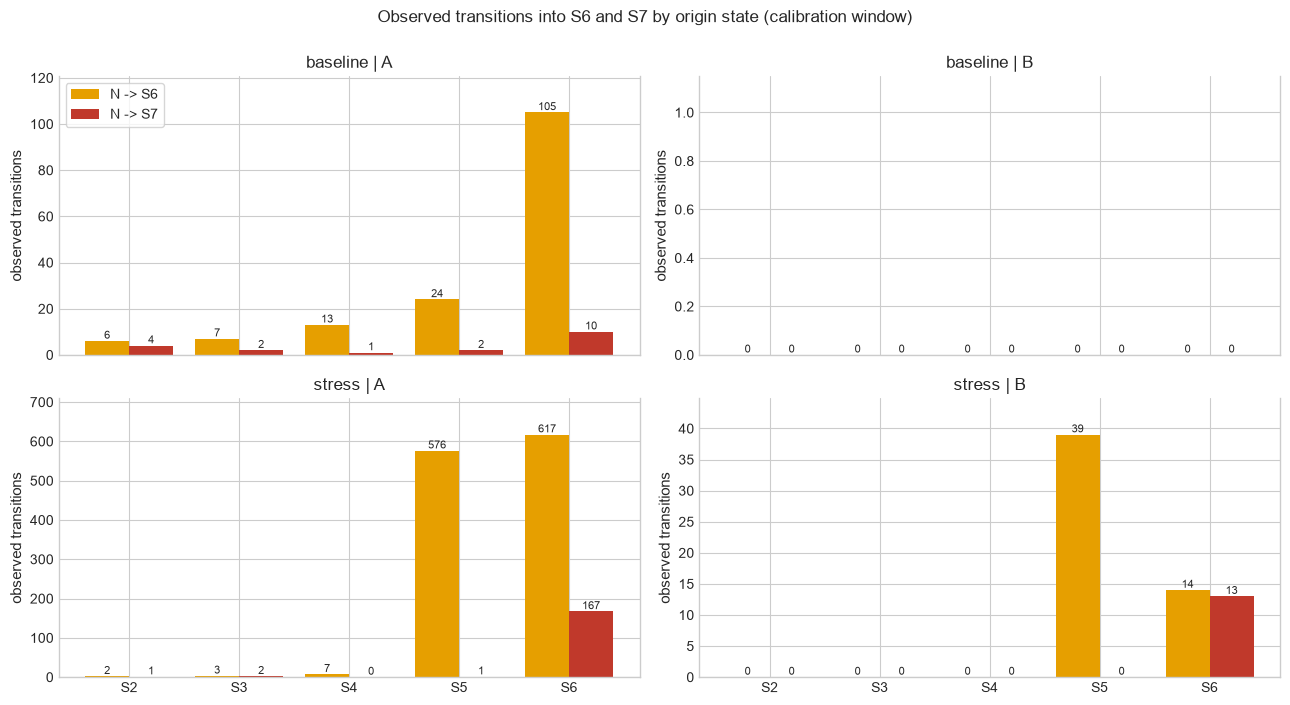

In [3]:
def annotated_matrix(daily: pd.DataFrame, counts: pd.DataFrame) -> pd.DataFrame:
    """Daily P as text ``p (N)`` per cell; absorbing rows show ``-`` instead of N."""
    text = pd.DataFrame(index=daily.index, columns=daily.columns, dtype=object)
    for row in daily.index:
        for col in daily.columns:
            n_cell = "-" if row in ABSORBING_STATES else f"{int(counts.loc[row, col]):,}"
            text.loc[row, col] = f"{daily.loc[row, col]:.4f} ({n_cell})"
    return text


depth_rows = []
for segment, entry in markov.items():
    print(f"\n{segment[0]} | profile {segment[1]}: daily P as `p (N)`")
    display(annotated_matrix(entry["P"], entry["N"]).style.set_properties(subset=["S6", "S7"], **{"background-color": "#fdebd0"}))
    for state in TRANSIENT_STATES:
        n_row = int(entry["N"].loc[state].sum())
        n_s6, n_s7 = int(entry["N"].loc[state, "S6"]), int(entry["N"].loc[state, "S7"])
        flags = []
        if n_row == 0:
            flags.append("EMPTY row")
        else:
            if n_row < MIN_ROW_DEPTH:
                flags.append(f"thin (<{MIN_ROW_DEPTH})")
            if n_s7 == 0:
                flags.append("no S7 transition")
            elif n_s7 < MIN_S7_EVENTS:
                flags.append(f"few S7 transitions (<{MIN_S7_EVENTS})")
        depth_rows.append(
            {"segment": segment_name(segment), "origin": state, "row depth": n_row, "N -> S6": n_s6, "N -> S7": n_s7,
             "daily P -> S7": entry["P"].loc[state, "S7"], "flag": "; ".join(flags) or "ok"}
        )  # fmt: skip
depth_table = pd.DataFrame(depth_rows)
print("\nDepth of the cells into S6 and S7 (origin states S2-S6):")
display(depth_table.set_index(["segment", "origin"]).style.format({"daily P -> S7": "{:.5f}"}))

fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
for ax, segment in zip(axes.ravel(), SEGMENTS):
    entry = markov[segment]
    x = np.arange(len(TRANSIENT_STATES))
    to_s6 = entry["N"].loc[TRANSIENT_STATES, "S6"].to_numpy()
    to_s7 = entry["N"].loc[TRANSIENT_STATES, "S7"].to_numpy()
    ax.bar(x - 0.2, to_s6, 0.4, label="N -> S6", color="#e69f00")
    ax.bar(x + 0.2, to_s7, 0.4, label="N -> S7", color="#c0392b")
    for xi, v6, v7 in zip(x, to_s6, to_s7):
        ax.text(xi - 0.2, v6, str(v6), ha="center", va="bottom", fontsize=8)
        ax.text(xi + 0.2, v7, str(v7), ha="center", va="bottom", fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels(TRANSIENT_STATES)
    ax.set_title(segment_name(segment))
    ax.set_ylim(0, max(int(to_s6.max()), int(to_s7.max()), 1) * 1.15)
    ax.set_ylabel("observed transitions")
axes[0, 0].legend()
plt.suptitle("Observed transitions into S6 and S7 by origin state (calibration window)", y=1.0)
plt.tight_layout()
plt.show()

## 4. $\mathbf{P}^{30}$ and the 30-day PD by state, with bootstrap intervals

$\mathbf{P}^{30}$ is the matrix power of the daily matrix of Section 3 (time-homogeneous chain over the 30 days). $\mathrm{PD}_i = [\mathbf{P}^{30}]_{i,S7}$ is the probability of a liquidation event within 30 days for a wallet that starts in state $i$. The interval is the 2.5%-97.5% percentile interval of the wallet-level (cluster) bootstrap of notebook 02 (B = 500). This `PD_i` is the one attached to every wallet of the valuation cohort in Part 2.


baseline_mar2024 | profile A: P^30


,S1,S2,S3,S4,S5,S6,S7
S1,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
S2,0.1353,0.7465,0.0889,0.0200,0.0054,0.0008,0.0032
S3,0.1361,0.6606,0.1387,0.0432,0.0127,0.0016,0.0071
S4,0.1445,0.5588,0.1831,0.0722,0.0225,0.0026,0.0163
S5,0.1415,0.4847,0.2082,0.0935,0.0302,0.0034,0.0384
S6,0.1371,0.3745,0.1831,0.0876,0.0288,0.0032,0.1856
S7,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000



baseline_mar2024 | profile B: P^30


,S1,S2,S3,S4,S5,S6,S7
S1,1.0000,0.0000,0.0000,0.0000,0.0000,0.0,0.0
S2,0.1077,0.6923,0.1478,0.0448,0.0074,0.0,0.0
S3,0.1070,0.5730,0.2099,0.0935,0.0166,0.0,0.0
S4,0.0852,0.4671,0.2656,0.1534,0.0287,0.0,0.0
S5,0.0745,0.4345,0.2835,0.1745,0.0330,0.0,0.0
S6,0.0000,0.0000,0.0000,0.0000,0.0000,1.0,0.0
S7,0.0000,0.0000,0.0000,0.0000,0.0000,0.0,1.0



stress_aug2024 | profile A: P^30


,S1,S2,S3,S4,S5,S6,S7
S1,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
S2,0.1079,0.4965,0.2344,0.1046,0.0378,0.0066,0.0122
S3,0.1173,0.2846,0.2740,0.1813,0.0813,0.0153,0.0461
S4,0.1320,0.1755,0.2459,0.2067,0.1054,0.0208,0.1138
S5,0.1358,0.1181,0.1999,0.1894,0.1025,0.0206,0.2337
S6,0.1091,0.0710,0.1273,0.1252,0.0689,0.0139,0.4846
S7,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000



stress_aug2024 | profile B: P^30


,S1,S2,S3,S4,S5,S6,S7
S1,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
S2,0.0451,0.4417,0.2710,0.1596,0.0505,0.0054,0.0268
S3,0.0459,0.3204,0.2741,0.2063,0.0724,0.0081,0.0728
S4,0.0459,0.2345,0.2564,0.2216,0.0818,0.0094,0.1505
S5,0.0457,0.1809,0.2183,0.1979,0.0742,0.0086,0.2745
S6,0.0138,0.0579,0.0720,0.0662,0.0249,0.0029,0.7624
S7,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000



30-day PD by starting state with the 95% wallet-bootstrap interval:


segment,baseline | A,baseline | B,stress | A,stress | B
state,,,,
S2,"0.0032 [0.0016, 0.0054]","0.0000 [0.0000, 0.0000]","0.0122 [0.0107, 0.0140]","0.0268 [0.0190, 0.0356]"
S3,"0.0071 [0.0040, 0.0106]","0.0000 [0.0000, 0.0000]","0.0461 [0.0416, 0.0506]","0.0728 [0.0518, 0.0973]"
S4,"0.0163 [0.0093, 0.0257]","0.0000 [0.0000, 0.0000]","0.1138 [0.1028, 0.1233]","0.1505 [0.1070, 0.1980]"
S5,"0.0384 [0.0191, 0.0655]","0.0000 [0.0000, 0.0000]","0.2337 [0.2133, 0.2517]","0.2745 [0.2081, 0.3492]"
S6,"0.1856 [0.0901, 0.2867]",n/a (empty row),"0.4846 [0.4489, 0.5222]","0.7624 [0.5876, 1.0000]"


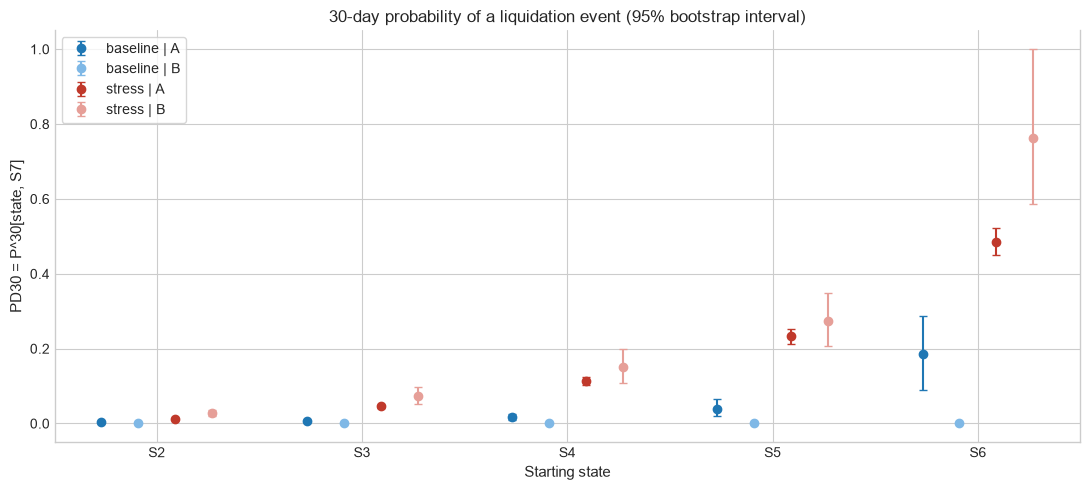

In [4]:
for segment, entry in markov.items():
    print(f"\n{segment[0]} | profile {segment[1]}: P^30")
    display(entry["P30"].round(4))

pd_long = []
for segment, entry in markov.items():
    for state in TRANSIENT_STATES:
        row = entry["pd"].loc[state]
        pd_long.append(
            {"segment": segment_name(segment), "state": state, "PD30": row["pd30"], "CI low": row["ci_low"], "CI high": row["ci_high"],
             "N -> S7 (daily)": int(row["n_to_S7"]), "row depth": int(row["row_depth"]), "estimated": bool(row["estimated"])}
        )  # fmt: skip
pd_long = pd.DataFrame(pd_long)
pd_text = pd_long.assign(
    cell=lambda f: np.where(
        f["estimated"],
        f["PD30"].map("{:.4f}".format) + " [" + f["CI low"].map("{:.4f}".format) + ", " + f["CI high"].map("{:.4f}".format) + "]",
        "n/a (empty row)",
    )
).pivot(index="state", columns="segment", values="cell")[SEGMENT_LABELS]
print("\n30-day PD by starting state with the 95% wallet-bootstrap interval:")
display(pd_text)

fig, ax = plt.subplots(figsize=(11, 5))
offsets = np.linspace(-0.27, 0.27, len(SEGMENTS))
colors = ["#1f77b4", "#7fb8e6", "#c0392b", "#e69f98"]
for offset, color, segment in zip(offsets, colors, SEGMENTS):
    table = markov[segment]["pd"].loc[TRANSIENT_STATES]
    x = np.arange(len(TRANSIENT_STATES)) + offset
    ax.errorbar(
        x, table["pd30"], yerr=[table["pd30"] - table["ci_low"], table["ci_high"] - table["pd30"]],
        fmt="o", capsize=3, color=color, label=segment_name(segment),
    )  # fmt: skip
ax.set_xticks(np.arange(len(TRANSIENT_STATES)))
ax.set_xticklabels(TRANSIENT_STATES)
ax.set_xlabel("Starting state")
ax.set_ylabel("PD30 = P^30[state, S7]")
ax.set_title("30-day probability of a liquidation event (95% bootstrap interval)")
ax.legend()
plt.tight_layout()
plt.show()

## 5. In-sample backtest on the day-1 cohort

**In-sample, by construction.** $\mathbf{P}$ was estimated on the 30 daily transitions of $[t-30, t]$, and the wallets of the day-1 cohort (observed on $t-30$, no late entrants) are the ones that generate most of those transitions. This is therefore a *consistency* check of the 30-day projection against its own calibration data, not a validation: it can only reveal that the Markov and time-homogeneity assumptions are wrong, never that the model predicts well out of sample. The out-of-time backtest ($t \to t+30$) is a later task and does not use this section.

**Design.**

- Cohort: wallets with `cohort = day1` (all `is_late_entrant = False`). Wallets that are already in `S7` on day 1 are not at risk and are reported on a separate line (they are excluded from every count below).
- Expected: $E[s] = \sum_i n_i \, [\mathbf{P}^{30}]_{i,s}$ with the starting counts $n_i$ of the cohort. In particular the expected number of liquidation events is $\sum_i n_i \, \mathrm{PD}_i$.
- Observed: `final_state` at $t$ (`S1` if the repay was observed, `S7` if a liquidation event was observed, otherwise the transient state at $t$). Wallets with `exit_reason = censored_window_end` are still in the filter at $t$ and **their state at $t$ is observed**; they are valid observations of the 30-day distribution.
- **Censored wallets** are those with `exit_reason = censored_filter_exit`: they left the profile filter with debt still open before $t$, so their state at $t$ is not observed (their `final_state` is the last state seen). They are reported on their own line and the comparison is shown **both** *including* them (kept in their last observed state: no absorption was seen for them) **and** *excluding* them (dropped from the expected and the observed).
- Significance: with independent wallets, the number of events is Poisson-binomial with probabilities $\mathrm{PD}_i$; the table gives the exact tail probability $P(X \ge \text{observed})$ and $P(X \le \text{observed})$. Independence is a strong assumption in stress (a common price shock), so these probabilities are indicative.

**Direction of the bias of censoring.** *Including* the censored wallets without an outcome gives an observed count of absorptions that is a **lower bound**: events that would have happened after the exit are missed, so "observed" is biased **down** and the model seems to over-predict. *Excluding* them conditions on staying in the filter. If the wallets that leave are mostly de-risking (partial repayments, collateral rotations), the remaining cohort is riskier than the full cohort and the observed rate is biased **up** relative to a model whose $\mathbf{P}$ is estimated with the transitions of all the wallets. The truth lies between the two comparisons; the informativeness check below shows which direction the data support.


baseline_mar2024 | profile A: IN-SAMPLE backtest, day-1 cohort (2024-02-14 -> 2024-03-15)
  wallets at risk (not in S7 on day 1): 2,519   already in S7 on day 1 (excluded): 0   censored by filter exit: 114 (4.5%)


including censored (last state)                                  excluding censored                                 
                             expected observed difference difference %           expected observed difference difference %
S1                             343.64    275.0     -68.64       -19.97             327.99    275.0     -52.99       -16.16
S2                            1774.01   1813.0      38.99         2.20            1696.43   1742.0      45.57         2.69
S3                             280.38    272.0      -8.38        -2.99             266.28    245.0     -21.28        -7.99
S4                              79.30    101.0      21.70        27.37              74.95     87.0      12.05        16.08
S5                              22.96     40.0      17.04        74.23              21.67     38.0      16.33        75.34
S6                               2.96      3.0       0.04         1.21               2.80      3.0       0.20         7.01
S7                              15.76     15.0      -0.76        -4.80              14.88     15.0       0.12         0.82
Total                         2519.00   2519.0       0.00          NaN            2405.00   2405.0       0.00          NaN


baseline_mar2024 | profile B: IN-SAMPLE backtest, day-1 cohort (2024-02-14 -> 2024-03-15)
  wallets at risk (not in S7 on day 1): 264   already in S7 on day 1 (excluded): 2   censored by filter exit: 12 (4.5%)


including censored (last state)                                  excluding censored                                 
                             expected observed difference difference %           expected observed difference difference %
S1                              27.99     21.0      -6.99       -24.98              26.70     21.0      -5.70       -21.36
S2                             173.43    184.0      10.57         6.10             165.48    177.0      11.52         6.96
S3                              43.88     42.0      -1.88        -4.29              41.92     37.0      -4.92       -11.74
S4                              15.95     13.0      -2.95       -18.50              15.27     13.0      -2.27       -14.84
S5                               2.75      3.0       0.25         9.12               2.63      3.0       0.37        13.95
S6                               0.00      0.0       0.00          NaN               0.00      0.0       0.00          NaN
S7                               0.00      1.0       1.00          NaN               0.00      1.0       1.00          NaN
Total                          264.00    264.0       0.00          NaN             252.00    252.0       0.00          NaN


stress_aug2024 | profile A: IN-SAMPLE backtest, day-1 cohort (2024-07-06 -> 2024-08-05)
  wallets at risk (not in S7 on day 1): 3,674   already in S7 on day 1 (excluded): 5   censored by filter exit: 128 (3.5%)


...

transitions into the state in N (all wallets)  day-1 wallets that end in the state  consistent (N >= cohort)
segment      outcome                                                                                                              
baseline | A S7                                                  19                                   15                      True
             S1                                                 384                                  275                      True
baseline | B S7                                                   0                                    1                     False
             S1                                                  31                                   21                      True
stress | A   S7                                                 171                                  132                      True
             S1                                                 473                                  291                      True
stress | B   S7                                                  13                                   13                      True
             S1                                                  17                                   13                      True

WARNING baseline | B: 1 day-1 wallet(s) end in S7 but N holds 0 such transitions (the origin-day profile of that wallet probably differs from its day-1 profile); its expected count is 0 by construction.

Is the censoring informative? (wallets that left the profile filter with debt open, before t)


segment,baseline | A,baseline | B,stress | A,stress | B
censored (n),114.000,12.000,128.000,14.000
censored (%),4.526,4.545,3.484,4.118
mean PD30 of start state: censored,0.008,0.000,0.083,0.105
mean PD30 of start state: not censored,0.006,0.000,0.075,0.096
expected S7 events hidden in censored,0.879,0.000,10.572,1.472
last state riskier than start (%),7.895,16.667,8.594,7.143
last state safer than start (%),24.561,0.000,12.500,21.429
start in S5-S6: censored (%),3.509,0.000,16.406,14.286
start in S5-S6: not censored (%),1.746,0.397,12.888,10.429



When do the observed S7 events of the day-1 cohort land? (time-homogeneity check, descriptive)


,observed S7 events,landing on t (%),landing in the last 3 days (%),landing in the first 15 days (%)
segment,,,,
baseline | A,15,13.3,20.0,53.3
baseline | B,1,0.0,0.0,0.0
stress | A,132,79.5,88.6,3.0
stress | B,13,76.9,100.0,0.0


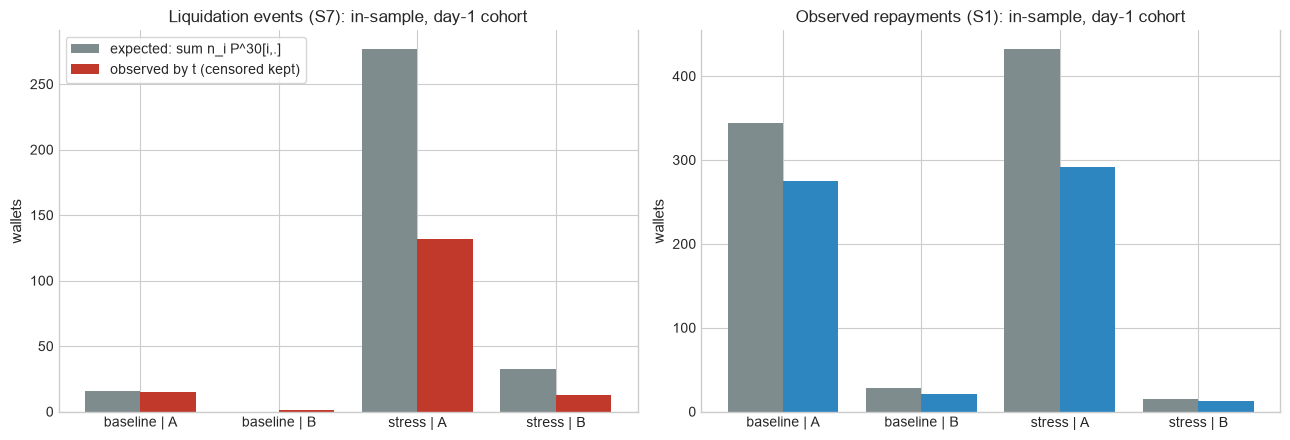

In [5]:
def poisson_binomial_pmf(probabilities: np.ndarray) -> np.ndarray:
    """Exact pmf of a sum of independent Bernoulli(p_i) (dynamic programming)."""
    pmf = np.zeros(len(probabilities) + 1)
    pmf[0] = 1.0
    for k, p in enumerate(probabilities, start=1):
        pmf[1 : k + 1] = pmf[1 : k + 1] * (1.0 - p) + pmf[0:k] * p
        pmf[0] *= 1.0 - p
    return pmf


def tail_probabilities(probabilities: np.ndarray, observed: int) -> tuple[float, float]:
    """P(X >= observed) and P(X <= observed) of a Poisson-binomial sum."""
    pmf = poisson_binomial_pmf(probabilities)
    assert abs(pmf.sum() - 1.0) < 1e-9 and abs((pmf * np.arange(len(pmf))).sum() - probabilities.sum()) < 1e-6
    return float(pmf[observed:].sum()), float(pmf[: observed + 1].sum())


day1 = cohorts_all.loc[cohorts_all["cohort"] == "day1"].copy().reset_index(drop=True)
assert not day1["is_late_entrant"].any(), "The day-1 cohort contains late entrants."
assert day1["final_state"].isin(STATE_ORDER).all() and day1["state"].isin(TRANSIENT_STATES + ["S7"]).all()
for scenario in SCENARIOS:
    assert set(day1.loc[day1["scenario"] == scenario, "date"]) == {DAY1_DATE[scenario]}, "Unexpected day-1 date."
# exit_reason and final_state are consistent
assert (day1.loc[day1["exit_reason"] == "S1_repay", "final_state"] == "S1").all()
assert day1.loc[day1["exit_reason"].isin(["S7_hf", "S7_liquidation_call"]), "final_state"].eq("S7").all()
assert day1.loc[day1["exit_reason"].str.startswith("censored"), "final_state"].isin(TRANSIENT_STATES).all()
day1["censored_exit"] = day1["exit_reason"].eq("censored_filter_exit")


def distribution_comparison(frame: pd.DataFrame, p30: pd.DataFrame) -> pd.DataFrame:
    """Expected (sum_i n_i P^30[i, s]) versus observed final state, for the wallets of ``frame`` (not in S7)."""
    start = frame["state"].value_counts().reindex(STATE_ORDER, fill_value=0).to_numpy(dtype=float)
    expected = start @ p30.to_numpy()
    observed = frame["final_state"].value_counts().reindex(STATE_ORDER, fill_value=0).to_numpy(dtype=float)
    assert abs(expected.sum() - len(frame)) < 1e-6 and observed.sum() == len(frame), "Totals do not match the cohort size."
    out = pd.DataFrame({"expected": expected, "observed": observed}, index=STATE_ORDER)
    out["difference"] = out["observed"] - out["expected"]
    out["difference %"] = np.where(out["expected"] > 1e-9, 100 * out["difference"] / out["expected"].where(out["expected"] > 1e-9), np.nan)
    return out


backtest_tables: dict[tuple[str, str], dict] = {}
headline_rows = []
informativeness_rows = []
for segment in SEGMENTS:
    p30 = markov[segment]["P30"]
    pd_state = markov[segment]["pd"]["pd30"]
    rows = day1.loc[(day1["scenario"] == segment[0]) & (day1["profile"] == segment[1])]
    already_s7 = rows.loc[rows["state"] == "S7"]
    at_risk = rows.loc[rows["state"] != "S7"]
    kept = at_risk.loc[~at_risk["censored_exit"]]
    censored = at_risk.loc[at_risk["censored_exit"]]

    incl = distribution_comparison(at_risk, p30)
    excl = distribution_comparison(kept, p30)
    table = pd.concat({"including censored (last state)": incl, "excluding censored": excl}, axis=1)
    table.loc["Total"] = table.sum(numeric_only=True)
    for version in ("including censored (last state)", "excluding censored"):
        total_expected, total_difference = table.loc["Total", (version, "expected")], table.loc["Total", (version, "difference")]
        assert abs(total_difference) < 1e-6 and abs(total_expected - table.loc["Total", (version, "observed")]) < 1e-6
        table.loc["Total", (version, "difference %")] = np.nan
    backtest_tables[segment] = {"table": table, "n_at_risk": len(at_risk), "n_censored": len(censored), "n_already_s7": len(already_s7)}

    print(f"\n{segment[0]} | profile {segment[1]}: IN-SAMPLE backtest, day-1 cohort ({DAY1_DATE[segment[0]]} -> {VALUATION_DATE[segment[0]]})")
    print(
        f"  wallets at risk (not in S7 on day 1): {len(at_risk):,}   already in S7 on day 1 (excluded): {len(already_s7)}   "
        f"censored by filter exit: {len(censored):,} ({100 * len(censored) / max(len(at_risk), 1):.1f}%)"
    )
    display(table.round(2))

    for target, label in (("S7", "liquidation events (S7)"), ("S1", "repayments (S1)")):
        for version, frame in (("including censored", at_risk), ("excluding censored", kept)):
            probabilities = frame["state"].map(p30[target]).to_numpy(dtype=float)
            observed = int((frame["final_state"] == target).sum())
            p_upper, p_lower = tail_probabilities(probabilities, observed)
            headline_rows.append(
                {"segment": segment_name(segment), "outcome": label, "cohort": version, "n": len(frame), "expected": probabilities.sum(),
                 "observed": observed, "observed / expected": observed / probabilities.sum() if probabilities.sum() > 0 else np.nan,
                 "P(X >= obs)": p_upper, "P(X <= obs)": p_lower}
            )  # fmt: skip

    start_share = lambda f: f["state"].value_counts(normalize=True).reindex(TRANSIENT_STATES, fill_value=0)  # noqa: E731
    last_state_rank = censored["final_state"].map({s: i for i, s in enumerate(STATE_ORDER)})
    start_rank = censored["state"].map({s: i for i, s in enumerate(STATE_ORDER)})
    informativeness_rows.append(
        {
            "segment": segment_name(segment), "censored (n)": len(censored), "censored (%)": 100 * len(censored) / max(len(at_risk), 1),
            "mean PD30 of start state: censored": censored["state"].map(pd_state).mean(),
            "mean PD30 of start state: not censored": kept["state"].map(pd_state).mean(),
            "expected S7 events hidden in censored": censored["state"].map(pd_state).sum(),
            "last state riskier than start (%)": 100 * float((last_state_rank > start_rank).mean()) if len(censored) else np.nan,
            "last state safer than start (%)": 100 * float((last_state_rank < start_rank).mean()) if len(censored) else np.nan,
            "start in S5-S6: censored (%)": 100 * start_share(censored).loc[["S5", "S6"]].sum() if len(censored) else np.nan,
            "start in S5-S6: not censored (%)": 100 * start_share(kept).loc[["S5", "S6"]].sum(),
        }
    )  # fmt: skip

headline = pd.DataFrame(headline_rows)
print("\nHeadline: expected versus observed absorptions, in-sample (exact Poisson-binomial tail probabilities)")
display(
    headline.set_index(["segment", "outcome", "cohort"]).style.format(
        {"expected": "{:.1f}", "observed / expected": "{:.2f}", "P(X >= obs)": "{:.3g}", "P(X <= obs)": "{:.3g}"}
    )
)

reconciliation_rows = []
for segment in SEGMENTS:
    params = segment_params.loc[(segment_params["scenario"] == segment[0]) & (segment_params["profile"] == segment[1])]
    rows = day1.loc[(day1["scenario"] == segment[0]) & (day1["profile"] == segment[1]) & (day1["state"] != "S7")]
    for outcome in ("S7", "S1"):
        in_matrix, in_cohort = int(params[f"n_{outcome}"].sum()), int((rows["final_state"] == outcome).sum())
        reconciliation_rows.append(
            {"segment": segment_name(segment), "outcome": outcome, "transitions into the state in N (all wallets)": in_matrix,
             "day-1 wallets that end in the state": in_cohort, "consistent (N >= cohort)": in_matrix >= in_cohort}
        )  # fmt: skip
reconciliation = pd.DataFrame(reconciliation_rows).set_index(["segment", "outcome"])
print("\nReconciliation: every absorption of a day-1 wallet must be one of the transitions counted in N of its segment")
display(reconciliation)
for (segment_label, outcome), row in reconciliation.iterrows():
    if not row["consistent (N >= cohort)"]:
        print(
            f"WARNING {segment_label}: {row.iloc[1]} day-1 wallet(s) end in {outcome} but N holds {row.iloc[0]} such transitions "
            "(the origin-day profile of that wallet probably differs from its day-1 profile); its expected count is 0 by construction."
        )

print("\nIs the censoring informative? (wallets that left the profile filter with debt open, before t)")
display(pd.DataFrame(informativeness_rows).set_index("segment").round(3).T)

timing_rows = []
for segment in SEGMENTS:
    events = day1.loc[(day1["scenario"] == segment[0]) & (day1["profile"] == segment[1]) & (day1["state"] != "S7") & (day1["final_state"] == "S7")]
    days_before_t = (pd.Timestamp(VALUATION_DATE[segment[0]]) - pd.to_datetime(events["event_date"])).dt.days
    timing_rows.append(
        {"segment": segment_name(segment), "observed S7 events": len(events),
         "landing on t (%)": 100 * float((days_before_t == 0).mean()) if len(events) else np.nan,
         "landing in the last 3 days (%)": 100 * float((days_before_t <= 2).mean()) if len(events) else np.nan,
         "landing in the first 15 days (%)": 100 * float((days_before_t >= 15).mean()) if len(events) else np.nan}
    )  # fmt: skip
print("\nWhen do the observed S7 events of the day-1 cohort land? (time-homogeneity check, descriptive)")
display(pd.DataFrame(timing_rows).set_index("segment").round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, target, label in zip(axes, ["S7", "S1"], ["Liquidation events (S7)", "Observed repayments (S1)"]):
    sub = headline.loc[(headline["outcome"].str.contains(target)) & (headline["cohort"] == "including censored")]
    x = np.arange(len(SEGMENTS))
    ax.bar(x - 0.2, sub["expected"], 0.4, label="expected: sum n_i P^30[i,.]", color="#7f8c8d")
    ax.bar(x + 0.2, sub["observed"], 0.4, label="observed by t (censored kept)", color="#c0392b" if target == "S7" else "#2e86c1")
    ax.set_xticks(x)
    ax.set_xticklabels(SEGMENT_LABELS)
    ax.set_title(label + ": in-sample, day-1 cohort")
    ax.set_ylabel("wallets")
axes[0].legend()
plt.tight_layout()
plt.show()

**Reading of the in-sample backtest.** The tables above give the facts; this is how they read.

1. **Baseline, profile A: consistent for liquidations, optimistic for repayments.** The expected number of liquidation events is close to the observed one (about 15.8 against 15; the exact tail probabilities are far from the extremes), while the expected number of repayments is clearly above the observed one (about 344 against 275).
2. **Stress: the homogeneous chain over-predicts liquidations by a factor of about two** (A: 277 expected against 132 observed; B: 33 against 13), and the observed distribution at $t$ is shifted towards `S5`-`S6` (A: 200 wallets in `S6` observed against 48 expected). The timing table explains why: roughly 80% of the observed `S7` events of the stress day-1 cohort land on $t$ itself, so the calibration sample is dominated by the last days of the window, whereas $\mathbf{P}^{30}$ applies that hazard from day 1. This is exactly the time-inhomogeneity that notebook 02 rejected in stress. Because of the causal convention, the liquidations *of* day $t$ are not part of the window: the wallets that sit in `S5`-`S6` at $t$ are the ones that will be liquidated afterwards. The exact tail probabilities are essentially zero but rest on independence between wallets, so they only say that the discrepancy is not noise.
3. **Repayments are over-predicted in all four segments** (by roughly 12% to 33%). A plausible reading, **not tested here**, is duration dependence: the pooled daily repayment probability includes the short spells of late entrants and of re-borrowers, which repay faster than the surviving wallets of day 1.
4. **Censoring is minor and does not drive the gap.** Only 3.5%-4.5% of the cohort leaves the filter with debt open; under the model they would hide about 1 liquidation in baseline A and about 11 in stress A, against a stress gap of about 145. The censored wallets start in slightly riskier states than the others but, once they leave, their last state is safer than their start more often than riskier, so excluding them lowers the expected count a little and leaves the ratio observed / expected almost unchanged (baseline A: 0.95 including, 1.01 excluding; stress A: 0.48 and 0.50). Neither of the two biases described above is large enough to matter here.
5. **Baseline B has an unexplained observed event.** One day-1 wallet of profile B ends in `S7` (a `liquidationCall` on 2024-03-06) while the count matrix of profile B holds no `S7` transition, so its expected count is exactly 0. The reconciliation table flags it: the wallet's origin-day profile in the transition table probably differs from its day-1 profile. It should be looked at in notebook 02; it does not affect any ECL figure (PD of profile B is 0 in every state).
6. **Scope.** This is a consistency check with the calibration sample, in-sample by construction. It supports the baseline PD as an order of magnitude; in stress it shows that the homogeneous 30-day projection does not reproduce the timing of the events. It says nothing about predictive power, which is the question of the out-of-time backtest.

---
# Part 2: EXPLORATORY LGD and ECL variants (menu for discussion with the tutor, NOT the final LGD)

From here on every number depends on choices that are still open. The variants below are **alternatives to discuss**; none of them is a recommendation, and the "base candidate" label of V1 only means that it is the formula currently written in `docs/decisions.md`. All variants share the same exposure and the same PD:

- $\mathrm{EAD}_w$ = `total_debt_usd` at $t$; $\mathrm{PD}_w$ = the 30-day PD of the state of wallet $w$ at $t$ (Section 4), for the wallets in `S2`-`S6`. Wallets already in `S7` at $t$ have $\mathrm{PD}_w = 1$ and sit on a separate line.
- $\mathrm{ECL}_w = \mathrm{EAD}_w \cdot \mathrm{PD}_w \cdot \mathrm{LGD}_w$.
- Collateral shares $s_k$ (value of collateral group $k$ over total collateral): `eth_core_usd` (ETH and ETH LSTs) $\to$ ETH shock; `wbtc_usd` $\to$ BTC shock; `uni_usd` $\to$ UNI shock; `link_usd` $\to$ LINK shock; `stable_usd` $\to$ 0 (parity). **LST shock = ETH shock** (decision). **Comonotonic shocks**: all assets fall simultaneously, each by its own expected shortfall (a conservative, explicit assumption that replaces copulas).
- The LT and LB of each wallet are the collateral-weighted `lt_w` and `lb_w` exported by notebook 02 (from `src.utils.protocol_params`, day by day); this weighting is an assumption still to be confirmed.

| Variant | Definition |
|---|---|
| **V0** "original project formula" | $\mathrm{LGD} = \max\!\big(0,\, 1 - \tfrac{C_w \sum_k s_k (1-\text{shock}_k)}{D_w}\big)$ with the **current** collateral $C_w$ and debt $D_w$ at $t$, ES 99% (1 day), no liquidation bonus |
| **V1** "conditional, real LT + bonus" (base candidate) | $\mathrm{LGD} = \max\!\big(0,\, 1 - \tfrac{HF_{entry}}{LT_w}\, \tfrac{\sum_k s_k (1-\text{shock}_k)}{1+LB_w}\big)$ with $HF_{entry} = 1$, ES 99% (1 day) |
| **V1nb** | V1 without the bonus ($LB_w = 0$): isolates the effect of the bonus |
| **V2** "empirical HF at entry (gap risk)" | V1 averaged over the empirical distribution of $HF_{entry}$ of the `S7` entries of the same scenario $\times$ profile calibration window |
| **V3** / **V3b** | V1 with ES 99.5% / ES 99.9% (1 day); 99.9% is **out of sample** for the 730-day window |
| **V4** ($h = 3$, $h = 5$) | V1 with the ES 99% of an $h$-day loss (Monte Carlo rows of notebook 03) |
| **S-depeg** | V1 with the stablecoin part of the collateral valued at 0.88 (USDC low of March 2023) |

**Why V1 conditions on the liquidation event.** If the position is liquidated when $HF = 1$, then $C/D = HF_{entry}/LT_w$. A liquidation repays debt $x$ and seizes $x(1+LB)$ of collateral, which improves $C/D$ if $C/D > 1+LB$ and worsens it if $C/D < 1+LB$; the threshold does not depend on whether the liquidation is partial or total. The 1-day ES shock hits the collateral between the trigger and the liquidation. With the 30-day PD this is coherent: the PD already contains the price path up to the trigger, and a 30-day shock in the LGD would count it twice.

**Why V0 is shown.** V0 is the formula of the original project. It applies the shock to the *current* position of a healthy wallet, so it asks "would a one-day crash from here wipe out the collateral?" instead of "what is lost once the wallet is liquidated?". It is shown only to document why it is (almost) zero and why it mixes PD and LGD.

## 6. LGD by variant

### 6.1 Shocks and break-even table

The shocks are the ES **price** shocks ($1 - e^{-L}$ conditioned on the tail, `es_price_shock`) of notebook 03. Variants V1, V1nb, V2 and S-depeg use ES 99% at one day (the closed-form row, checked against the notebook-03 base export); V3 uses 99.5% and V3b 99.9% (closed form, one day); V4 uses the Monte Carlo rows of $h = 3$ and $h = 5$ days at 99%. The break-even table gives, for a wallet entirely in one asset, the shock at which a liquidation at $HF_{entry}=1$ starts to lose money: $1 - LT$ without bonus and $1 - LT(1+LB)$ with bonus. If the ES is below the break-even shock the LGD of that asset is exactly 0.

In [6]:
GROUP_ASSET = {"eth_core_usd": "ETH", "wbtc_usd": "BTC", "uni_usd": "UNI", "link_usd": "LINK", "stable_usd": None}
# eth_core_usd contains WETH and the ETH liquid staking tokens: LST shock = ETH shock (decision).
assert GROUP_ASSET["eth_core_usd"] == "ETH" and GROUP_ASSET["stable_usd"] is None
assert list(GROUP_ASSET) == COLLATERAL_GROUPS

SHOCK_SPECS = {
    "ES99_h1": (0.99, 1, "closed_form"),
    "ES995_h1": (0.995, 1, "closed_form"),
    "ES999_h1": (0.999, 1, "closed_form"),
    "ES99_h3": (0.99, 3, "monte_carlo"),
    "ES99_h5": (0.99, 5, "monte_carlo"),
}
DEPEG_STABLE_SHOCK = 0.12  # stablecoin collateral valued at 0.88


def asset_shocks(scenario: str, spec: str) -> pd.Series:
    """ES price shock of every asset (ETH, BTC, UNI, LINK) for a scenario and a shock specification."""
    confidence, horizon, method = SHOCK_SPECS[spec]
    rows = shock_grid.loc[
        (shock_grid["scenario"] == scenario)
        & np.isclose(shock_grid["confidence_level"], confidence)
        & (shock_grid["horizon_days"] == horizon)
        & (shock_grid["method"] == method)
    ]
    assert len(rows) == 4 and rows["asset"].is_unique, f"{scenario}/{spec}: expected one row per asset, got {len(rows)}."
    shocks = rows.set_index("asset")["es_price_shock"].astype(float)
    assert shocks.between(0, 1).all() and set(shocks.index) == {"ETH", "BTC", "UNI", "LINK"}
    return shocks


def group_shock_vector(scenario: str, spec: str, stable_shock: float = 0.0) -> np.ndarray:
    """Shock of the five collateral groups (ETH core/LST, WBTC, UNI, LINK, stable) in COLLATERAL_GROUPS order."""
    shocks = asset_shocks(scenario, spec)
    vector = np.array([shocks[GROUP_ASSET[group]] if GROUP_ASSET[group] else stable_shock for group in COLLATERAL_GROUPS])
    return vector


# consistency: the ES 99% closed-form one-day shocks equal the base export of notebook 03
for scenario in SCENARIOS:
    exported = base_shocks.loc[(base_shocks["scenario"] == scenario) & np.isclose(base_shocks["confidence_level"], 0.99)].set_index("asset")["es_price_shock"]
    gap = float((exported - asset_shocks(scenario, "ES99_h1")).abs().max())
    assert gap < 1e-12, f"{scenario}: ES99 h=1 shocks differ from the notebook-03 base export ({gap:.2e})."
    # the Monte Carlo ES at h=1 should agree with the closed form (sampling error only)
    mc_h1 = shock_grid.loc[(shock_grid["scenario"] == scenario) & (shock_grid["method"] == "monte_carlo") & np.isclose(shock_grid["confidence_level"], 0.99) & (shock_grid["horizon_days"] == 1)].set_index("asset")["es_price_shock"]
    assert (mc_h1 / asset_shocks(scenario, "ES99_h1") - 1).abs().max() < 0.01, "MC h=1 differs from the closed form by more than 1%."
    # stable shock is zero and the LST uses the ETH shock in every base vector
    vector = group_shock_vector(scenario, "ES99_h1")
    assert vector[COLLATERAL_GROUPS.index("stable_usd")] == 0.0
    assert vector[COLLATERAL_GROUPS.index("eth_core_usd")] == asset_shocks(scenario, "ES99_h1")["ETH"]
print("ES99 h=1 closed-form shocks equal the notebook-03 base export; stable shock = 0; LST (eth_core) shock = ETH shock.")

shock_rows = []
for scenario in SCENARIOS:
    for spec, (confidence, horizon, method) in SHOCK_SPECS.items():
        shocks = asset_shocks(scenario, spec)
        flag = shock_grid.loc[
            (shock_grid["scenario"] == scenario) & np.isclose(shock_grid["confidence_level"], confidence)
            & (shock_grid["horizon_days"] == horizon) & (shock_grid["method"] == method), "out_of_sample_flag"
        ].any()  # fmt: skip
        shock_rows.append({"scenario": scenario, "spec": spec, "method": method, **shocks.to_dict(), "out-of-sample": bool(flag)})
shock_table = pd.DataFrame(shock_rows).set_index(["scenario", "spec"])[["method", "ETH", "BTC", "UNI", "LINK", "out-of-sample"]]
print("\nES price shocks used (fraction of the price lost):")
display(shock_table.style.format({a: "{:.4f}" for a in ["ETH", "BTC", "UNI", "LINK"]}))

breakeven_check = breakeven.copy()
assert np.allclose(breakeven_check["breakeven_no_bonus"], 1 - breakeven_check["lt"], atol=1e-12)
assert np.allclose(breakeven_check["breakeven_with_bonus"], 1 - breakeven_check["lt"] * (1 + breakeven_check["lb"]), atol=1e-12)
breakeven_check["ES99 h=1 shock"] = [asset_shocks(s, "ES99_h1")[a] for s, a in zip(breakeven_check["scenario"], breakeven_check["asset"])]
breakeven_check["ES99.5 h=1 shock"] = [asset_shocks(s, "ES995_h1")[a] for s, a in zip(breakeven_check["scenario"], breakeven_check["asset"])]
breakeven_check["ES99 > break-even (no bonus)?"] = breakeven_check["ES99 h=1 shock"] > breakeven_check["breakeven_no_bonus"]
breakeven_check["ES99 > break-even (bonus)?"] = breakeven_check["ES99 h=1 shock"] > breakeven_check["breakeven_with_bonus"]
breakeven_check["ES99.5 > break-even (bonus)?"] = breakeven_check["ES99.5 h=1 shock"] > breakeven_check["breakeven_with_bonus"]
print("\nBreak-even shocks (Aave LT/LB) versus the ES shocks: LGD > 0 at HF_entry = 1 only where ES > break-even")
display(breakeven_check.set_index(["scenario", "aave_symbol"]).drop(columns=["asset"]).round(4))

ES99 h=1 closed-form shocks equal the notebook-03 base export; stable shock = 0; LST (eth_core) shock = ETH shock.

ES price shocks used (fraction of the price lost):



Break-even shocks (Aave LT/LB) versus the ES shocks: LGD > 0 at HF_entry = 1 only where ES > break-even


lt    lb  breakeven_no_bonus  breakeven_with_bonus  ES99 h=1 shock  ES99.5 h=1 shock  ES99 > break-even (no bonus)?  ES99 > break-even (bonus)?  ES99.5 > break-even (bonus)?
scenario         aave_symbol                                                                                                                                                                                 
baseline_mar2024 WETH         0.83  0.05                0.17                0.1285          0.1388            0.1651                          False                        True                          True
                 wstETH       0.81  0.06                0.19                0.1414          0.1388            0.1651                          False                       False                          True
                 WBTC         0.78  0.05                0.22                0.1810          0.1149            0.1393                          False                       False                         False
                 UNI          0.77  0.10                0.23                0.1530          0.1497            0.1709                          False                       False                          True
                 LINK         0.68  0.07                0.32                0.2724          0.1566            0.1816                          False                       False                         False
stress_aug2024   WETH         0.83  0.05                0.17                0.1285          0.1205            0.1428                          False                       False                          True
                 wstETH       0.81  0.06                0.19                0.1414          0.1205            0.1428                          False                       False                          True
                 WBTC         0.78  0.05                0.22                0.1810          0.0941            0.1097                          False                       False                         False
                 UNI          0.74  0.10                0.26                0.1860          0.1413            0.1606                          False                       False                         False
                 LINK         0.68  0.07                0.32                0.2724          0.1382            0.1627                          False                       False                         False

### 6.2 LGD functions, with unit checks

`lgd_current_position` is V0; `lgd_at_entry` is V1 (and V1nb, V3, V4, S-depeg through the shock vector, the bonus switch and the stable shock); `lgd_empirical_entry` is V2. All return values in $[0, 1]$. The unit checks tie the code to the break-even table: for a synthetic wallet entirely in one asset, $\mathrm{LGD}_{V1} > 0$ exactly when the ES shock exceeds `breakeven_with_bonus` (and V1nb exactly when it exceeds `breakeven_no_bonus`).

In [7]:
def collateral_retention(frame: pd.DataFrame, shock_vectors: dict[str, np.ndarray]) -> np.ndarray:
    """Sum_k s_k (1 - shock_k): share of the collateral value that survives a comonotonic shock."""
    shares = frame[COLLATERAL_GROUPS].to_numpy(dtype=float) / frame[["total_collateral_usd"]].to_numpy(dtype=float)
    shock_matrix = np.vstack(frame["scenario"].map(shock_vectors).to_list())
    return (shares * (1.0 - shock_matrix)).sum(axis=1)


def lgd_current_position(collateral: np.ndarray, debt: np.ndarray, retention: np.ndarray) -> np.ndarray:
    """V0: max(0, 1 - C (1 - shock) / D) on the current position, no bonus."""
    return np.maximum(0.0, 1.0 - (collateral / debt) * retention)


def lgd_at_entry(hf_entry: np.ndarray, lt_w: np.ndarray, lb_w: np.ndarray, retention: np.ndarray, bonus: bool = True) -> np.ndarray:
    """V1: max(0, 1 - (HF_entry / LT_w) * retention / (1 + LB_w)); ``bonus=False`` drops the (1 + LB_w) factor."""
    return np.maximum(0.0, 1.0 - (hf_entry / lt_w) * retention / ((1.0 + lb_w) if bonus else 1.0))


def lgd_empirical_entry(entry_pool: np.ndarray, lt_w: np.ndarray, lb_w: np.ndarray, retention: np.ndarray) -> np.ndarray:
    """V2: V1 averaged over an empirical sample of HF_entry values (equal weights)."""
    coverage = (entry_pool[None, :] / lt_w[:, None]) * (retention / (1.0 + lb_w))[:, None]
    return np.maximum(0.0, 1.0 - coverage).mean(axis=1)


unit_rows = []
for _, row in breakeven.iterrows():
    shock = asset_shocks(row["scenario"], "ES99_h1")[row["asset"]]
    retention = np.array([1.0 - shock])
    lgd_bonus = lgd_at_entry(np.array([1.0]), np.array([row["lt"]]), np.array([row["lb"]]), retention)[0]
    lgd_no_bonus = lgd_at_entry(np.array([1.0]), np.array([row["lt"]]), np.array([row["lb"]]), retention, bonus=False)[0]
    assert (lgd_bonus > 0) == (shock > row["breakeven_with_bonus"]), f"V1 sign mismatch for {row['scenario']}/{row['aave_symbol']}."
    assert (lgd_no_bonus > 0) == (shock > row["breakeven_no_bonus"]), f"V1nb sign mismatch for {row['scenario']}/{row['aave_symbol']}."
    assert lgd_bonus >= lgd_no_bonus
    assert abs(lgd_bonus - max(0.0, 1.0 - (1.0 / row["lt"]) * (1.0 - shock) / (1.0 + row["lb"]))) < 1e-15
    unit_rows.append({"scenario": row["scenario"], "asset": row["aave_symbol"], "ES99 shock": shock, "LGD V1": lgd_bonus, "LGD V1nb": lgd_no_bonus})
print("Unit checks passed: LGD V1 > 0 iff ES99 > break-even with bonus; V1nb > 0 iff ES99 > break-even without bonus; V1 >= V1nb.")
display(pd.DataFrame(unit_rows).set_index(["scenario", "asset"]).style.format("{:.4f}"))

Unit checks passed: LGD V1 > 0 iff ES99 > break-even with bonus; V1nb > 0 iff ES99 > break-even without bonus; V1 >= V1nb.


### 6.3 Empirical Health Factor at `S7` entry (input of V2) and liquidation latency

V2 needs the distribution of the Health Factor at which wallets actually enter `S7`. The entries observed in the calibration window $[t-30, t]$ are taken from the cohort file:

- `day1` cohort wallets that **end in `S7`** by $t$ (the calibration outcome), **excluding the wallets already in `S7` on day 1** (they are persistent under-water positions, most of them never liquidated, not transitions into `S7`), and
- valuation-cohort wallets that are in `S7` at $t$ (their entry falls in the last interval of the window) and are not already counted from the day-1 cohort (late entrants, re-entries).

Each wallet appears once. For an entry triggered by the Health Factor (`s7_trigger = hf`) the observed `hf_at_s7_entry` ($\le 1$) is used; for an entry triggered by a `liquidationCall` the previous-day HF is above 1 by construction, so $HF_{entry} = 1$ (the Health Factor at the moment of the liquidation). **If a segment has fewer than 10 entries, the entries of profiles A and B of the same scenario are pooled and the segment is flagged.** The `oot_*` columns are not used; the entries of $(t, t+30]$ are not part of the calibration window.

**Latency.** `days_s7_to_liquidation` is the number of days from the first snapshot with $HF \le 1$ to the first `liquidationCall` (0 for a `liquidationCall` entry by construction; empty if no liquidation followed). It describes how long a wallet stays under water before it is liquidated and is *not* an input of any variant below: the horizons $h = 3, 5$ of V4 are fixed scenarios. Note that this variable can look beyond $t$ (the event file spans $t+30$), so it is descriptive only.

In [8]:
MIN_POOL_ENTRIES = 10


def build_s7_entry_pool(cohorts: pd.DataFrame, include_initial_s7: bool = False) -> pd.DataFrame:
    """S7 entries of the calibration window with the HF_entry used by V2 (one row per wallet).

    Wallets already in S7 on day 1 (persistent under-water positions, not transitions) are left out unless
    ``include_initial_s7`` is True (sensitivity only).
    """
    day1_rows = cohorts.loc[cohorts["cohort"] == "day1"]
    day1_s7_wallets = day1_rows.loc[day1_rows["final_state"] == "S7", ["scenario", "user_id"]]
    keep_day1 = (day1_rows["final_state"] == "S7") & ((day1_rows["state"] != "S7") | include_initial_s7)
    entries_day1 = day1_rows.loc[keep_day1].assign(source="day-1 cohort")
    valuation_s7 = cohorts.loc[(cohorts["cohort"] == "valuation") & (cohorts["state"] == "S7")]
    merged = valuation_s7.merge(day1_s7_wallets.assign(_in_day1=True), on=["scenario", "user_id"], how="left")
    entries_valuation = merged.loc[merged["_in_day1"].isna()].drop(columns="_in_day1").assign(source="valuation cohort (late/re-entry)")
    pool = pd.concat([entries_day1, entries_valuation], ignore_index=True)
    assert pool["s7_trigger"].isin(["hf", "liquidation_call"]).all(), "An S7 entry without trigger."
    assert not pool.duplicated(["scenario", "user_id"]).any()
    hf_trigger = pool["s7_trigger"] == "hf"
    assert (pool.loc[hf_trigger, "hf_at_s7_entry"] <= 1.0 + 1e-9).all(), "An hf-triggered S7 entry has HF > 1."
    assert pool.loc[hf_trigger, "hf_at_s7_entry"].notna().all(), "An hf-triggered S7 entry without HF."
    pool["hf_entry"] = np.where(hf_trigger, np.minimum(pool["hf_at_s7_entry"], 1.0), 1.0)
    return pool[["scenario", "profile", "user_id", "source", "s7_trigger", "hf_at_s7_entry", "hf_entry", "days_s7_to_liquidation"]]


s7_pool = build_s7_entry_pool(cohorts_all)

entry_pools: dict[tuple[str, str], np.ndarray] = {}
pool_flags: dict[tuple[str, str], str] = {}
for segment in SEGMENTS:
    own = s7_pool.loc[(s7_pool["scenario"] == segment[0]) & (s7_pool["profile"] == segment[1]), "hf_entry"].to_numpy()
    if len(own) >= MIN_POOL_ENTRIES:
        entry_pools[segment], pool_flags[segment] = own, "own segment"
    else:
        entry_pools[segment] = s7_pool.loc[s7_pool["scenario"] == segment[0], "hf_entry"].to_numpy()
        pool_flags[segment] = f"POOLED A+B (own segment has only {len(own)} entries)"
    assert len(entry_pools[segment]) >= MIN_POOL_ENTRIES, f"{segment}: fewer than {MIN_POOL_ENTRIES} entries even pooled."


def quantile_row(values: np.ndarray) -> dict:
    """Min, quartiles, median, max and share below 1 of an HF_entry sample."""
    return {"n": len(values), "min": values.min(), "p25": np.quantile(values, 0.25), "median": np.median(values),
            "p75": np.quantile(values, 0.75), "max": values.max(), "share HF_entry < 1 (%)": 100 * float((values < 1.0 - 1e-12).mean())}  # fmt: skip


pool_rows = []
for segment in SEGMENTS:
    own = s7_pool.loc[(s7_pool["scenario"] == segment[0]) & (s7_pool["profile"] == segment[1])]
    pool_rows.append(
        {"segment": segment_name(segment), "entries": len(own), "via hf": int((own["s7_trigger"] == "hf").sum()),
         "via liquidationCall": int((own["s7_trigger"] == "liquidation_call").sum()), "V2 uses": pool_flags[segment],
         **{f"V2 pool {k}": v for k, v in quantile_row(entry_pools[segment]).items() if k != "n"}, "V2 pool n": len(entry_pools[segment])}
    )  # fmt: skip
print("S7 entries of the calibration window and the HF_entry sample V2 uses (HF_entry = 1 for liquidationCall entries):")
display(pd.DataFrame(pool_rows).set_index("segment").T)

hf_entries = s7_pool.loc[s7_pool["s7_trigger"] == "hf"]
print("\nEntries triggered by the Health Factor (the only ones with HF_entry < 1) and their latency to the first liquidationCall:")
latency_rows = []
for segment in SEGMENTS:
    own = hf_entries.loc[(hf_entries["scenario"] == segment[0]) & (hf_entries["profile"] == segment[1])]
    liquidated = own["days_s7_to_liquidation"].dropna()
    latency_rows.append(
        {"segment": segment_name(segment), "hf entries": len(own), "never liquidated in the file": int(own["days_s7_to_liquidation"].isna().sum()),
         "liquidated: n": len(liquidated), "days median": liquidated.median() if len(liquidated) else np.nan,
         "days mean": liquidated.mean() if len(liquidated) else np.nan, "days max": liquidated.max() if len(liquidated) else np.nan,
         "HF_entry min": own["hf_entry"].min() if len(own) else np.nan, "HF_entry median": own["hf_entry"].median() if len(own) else np.nan}
    )  # fmt: skip
latency = pd.DataFrame(latency_rows).set_index("segment")
display(latency)
initial_s7 = day1.loc[day1["state"] == "S7"]
print("\nWallets already in S7 on day 1 (excluded from the V2 pool): persistent under-water positions that were not liquidated")
display(
    initial_s7.groupby(["scenario", "profile"]).agg(
        n=("user_id", "size"), debt_usd_median=("total_debt_usd", "median"), hf_min=("health_factor", "min"),
        hf_median=("health_factor", "median"), never_liquidated=("days_s7_to_liquidation", lambda x: int(x.isna().sum())),
    )
)
share_same_interval = (s7_pool["s7_trigger"] == "liquidation_call").groupby([s7_pool["scenario"], s7_pool["profile"]]).mean()
print("Share of S7 entries that were liquidated inside the daily interval in which they crossed HF = 1 (liquidationCall entries, latency 0 by construction):")
display(share_same_interval.rename("share").to_frame().style.format("{:.1%}"))

S7 entries of the calibration window and the HF_entry sample V2 uses (HF_entry = 1 for liquidationCall entries):


segment,baseline | A,baseline | B,stress | A,stress | B
entries,16,1,154,14
via hf,5,0,0,0
via liquidationCall,11,1,154,14
V2 uses,own segment,POOLED A+B (own segment has only 1 entries),own segment,own segment
V2 pool min,0.984549,0.984549,1.0,1.0
V2 pool p25,0.996231,0.996639,1.0,1.0
V2 pool median,1.0,1.0,1.0,1.0
V2 pool p75,1.0,1.0,1.0,1.0
V2 pool max,1.0,1.0,1.0,1.0
V2 pool share HF_entry < 1 (%),31.25,29.411765,0.0,0.0



Entries triggered by the Health Factor (the only ones with HF_entry < 1) and their latency to the first liquidationCall:


,hf entries,never liquidated in the file,liquidated: n,days median,days mean,days max,HF_entry min,HF_entry median
segment,,,,,,,,
baseline | A,5,2,3,4.0,3.666667,7.0,0.984549,0.993971
baseline | B,0,0,0,NaN,NaN,NaN,NaN,NaN
stress | A,0,0,0,NaN,NaN,NaN,NaN,NaN
stress | B,0,0,0,NaN,NaN,NaN,NaN,NaN



Wallets already in S7 on day 1 (excluded from the V2 pool): persistent under-water positions that were not liquidated


,,n,debt_usd_median,hf_min,hf_median,never_liquidated
scenario,profile,,,,,
baseline_mar2024,B,2,714.777271,0.660625,0.822033,1
stress_aug2024,A,5,362.408861,0.000010,0.003615,4


Share of S7 entries that were liquidated inside the daily interval in which they crossed HF = 1 (liquidationCall entries, latency 0 by construction):


### 6.4 LGD of every wallet under every variant

Wallets in `S2`-`S6` take $HF_{entry} = 1$ (V1-family) or the empirical sample (V2). Wallets already in `S7` at $t$ take their own entry, $HF_{entry} = \min(1, HF_{observed})$, in every variant of the V1 family (including V2: the entry has already happened, so no distribution is needed); V0 uses the current $C_w, D_w$ as for everybody. Assertions: $0 \le \mathrm{LGD}_w \le 1$ and no missing value. A memo after the assertions shows how fragile V2 is to the treatment of the wallets that were already in `S7` on day 1.

In [9]:
VARIANT_ORDER = ["V0", "V1nb", "V1", "V2", "V3", "V3b", "V4_h3", "V4_h5", "S_depeg"]
VARIANT_DESCRIPTION = {
    "V0": "original formula, current position, ES99 h=1, no bonus",
    "V1nb": "V1 without liquidation bonus",
    "V1": "conditional on the event, HF_entry=1, LT_w, bonus, ES99 h=1 (base candidate)",
    "V2": "V1 averaged over empirical HF_entry of S7 entries (gap risk)",
    "V3": "V1 with ES 99.5% h=1",
    "V3b": "V1 with ES 99.9% h=1 (OUT OF SAMPLE)",
    "V4_h3": "V1 with ES99 of a 3-day loss (Monte Carlo)",
    "V4_h5": "V1 with ES99 of a 5-day loss (Monte Carlo)",
    "S_depeg": "V1 with stablecoin collateral valued at 0.88",
}
display(pd.DataFrame({"variant": VARIANT_ORDER, "description": [VARIANT_DESCRIPTION[v] for v in VARIANT_ORDER]}).set_index("variant"))

# ---- PD of every wallet --------------------------------------------------------------------------------
pd_lookup = pd.concat(
    {segment: entry["pd"][["pd30", "ci_low", "ci_high", "estimated"]] for segment, entry in markov.items()},
    names=["scenario", "profile"],
).reset_index().rename(columns={"current_state": "state", "pd30": "pd_point", "ci_low": "pd_low", "ci_high": "pd_high"})
valuation = valuation.merge(pd_lookup, on=["scenario", "profile", "state"], how="left", validate="many_to_one")
assert valuation[["pd_point", "pd_low", "pd_high"]].notna().all().all()
is_s7 = (valuation["state"] == "S7").to_numpy()
assert (valuation.loc[is_s7, ["pd_point", "pd_low", "pd_high"]] == 1.0).all().all(), "PD of S7 at valuation must be 1."
n_unestimated = int((~valuation["estimated"].astype(bool)).sum())
print(f"Valuation wallets whose state has no estimated PD (empty row, PD placeholder 0): {n_unestimated}")

# ---- LGD per variant -----------------------------------------------------------------------------------
shock_by_spec = {
    spec: {scenario: group_shock_vector(scenario, spec) for scenario in SCENARIOS} for spec in SHOCK_SPECS
}
depeg_vectors = {scenario: group_shock_vector(scenario, "ES99_h1", stable_shock=DEPEG_STABLE_SHOCK) for scenario in SCENARIOS}
retention = {spec: collateral_retention(valuation, vectors) for spec, vectors in shock_by_spec.items()}
retention["depeg"] = collateral_retention(valuation, depeg_vectors)
assert all((r > 0).all() and (r <= 1 + 1e-12).all() for r in retention.values())

lt_w, lb_w = valuation["lt_w"].to_numpy(), valuation["lb_w"].to_numpy()
collateral, debt = valuation["total_collateral_usd"].to_numpy(), valuation["total_debt_usd"].to_numpy()
hf_entry_v1 = np.where(is_s7, np.minimum(1.0, valuation["health_factor"].to_numpy()), 1.0)

lgd: dict[str, np.ndarray] = {}
lgd["V0"] = lgd_current_position(collateral, debt, retention["ES99_h1"])
lgd["V1nb"] = lgd_at_entry(hf_entry_v1, lt_w, lb_w, retention["ES99_h1"], bonus=False)
lgd["V1"] = lgd_at_entry(hf_entry_v1, lt_w, lb_w, retention["ES99_h1"])
lgd["V2"] = lgd["V1"].copy()  # S7 at valuation keeps its own entry
for segment in SEGMENTS:
    mask = ((valuation["scenario"] == segment[0]) & (valuation["profile"] == segment[1]) & ~is_s7).to_numpy()
    lgd["V2"][mask] = lgd_empirical_entry(entry_pools[segment], lt_w[mask], lb_w[mask], retention["ES99_h1"][mask])
lgd["V3"] = lgd_at_entry(hf_entry_v1, lt_w, lb_w, retention["ES995_h1"])
lgd["V3b"] = lgd_at_entry(hf_entry_v1, lt_w, lb_w, retention["ES999_h1"])
lgd["V4_h3"] = lgd_at_entry(hf_entry_v1, lt_w, lb_w, retention["ES99_h3"])
lgd["V4_h5"] = lgd_at_entry(hf_entry_v1, lt_w, lb_w, retention["ES99_h5"])
lgd["S_depeg"] = lgd_at_entry(hf_entry_v1, lt_w, lb_w, retention["depeg"])

for variant in VARIANT_ORDER:
    values = lgd[variant]
    assert values.shape == (len(valuation),) and np.isfinite(values).all(), f"{variant}: invalid LGD."
    assert (values >= 0).all() and (values <= 1 + 1e-12).all(), f"{variant}: LGD outside [0, 1]."
# monotonicity checks implied by the definitions
assert (lgd["V1"] >= lgd["V1nb"] - 1e-15).all(), "The bonus must not reduce the LGD."
assert (lgd["V3"] >= lgd["V1"] - 1e-15).all() and (lgd["V3b"] >= lgd["V3"] - 1e-15).all(), "A higher ES level must not reduce the LGD."
assert (lgd["V4_h5"] >= lgd["V4_h3"] - 1e-15).all() and (lgd["V4_h3"] >= lgd["V1"] - 1e-15).all()
assert (lgd["S_depeg"] >= lgd["V1"] - 1e-15).all()
assert (lgd["V2"] >= lgd["V1"] - 1e-15).all(), "HF_entry <= 1 in the pool: V2 cannot be below V1."
print("LGD assertions passed for all variants: finite, 0 <= LGD <= 1, and the expected orderings V1nb <= V1 <= V2, V1 <= V3 <= V3b, V1 <= V4_h3 <= V4_h5, V1 <= S_depeg.")

# ---- memo: V2 if the persistent under-water positions of day 1 were treated as S7 entries -----------------
pool_with_initial = build_s7_entry_pool(cohorts_all, include_initial_s7=True)
lgd_v2_memo = lgd["V1"].copy()
memo_rows = []
for segment in SEGMENTS:
    mask = ((valuation["scenario"] == segment[0]) & (valuation["profile"] == segment[1]) & ~is_s7).to_numpy()
    own = pool_with_initial.loc[(pool_with_initial["scenario"] == segment[0]) & (pool_with_initial["profile"] == segment[1]), "hf_entry"].to_numpy()
    sample = own if len(own) >= MIN_POOL_ENTRIES else pool_with_initial.loc[pool_with_initial["scenario"] == segment[0], "hf_entry"].to_numpy()
    lgd_v2_memo[mask] = lgd_empirical_entry(sample, lt_w[mask], lb_w[mask], retention["ES99_h1"][mask])
    ead_all = valuation["total_debt_usd"].to_numpy()
    ead_pd = ead_all * valuation["pd_point"].to_numpy()
    memo_rows.append(
        {"segment": segment_name(segment), "pool size": len(sample), "entries with HF_entry < 0.5": int((sample < 0.5).sum()),
         "V2 as defined: ECL/EAD S2-S6 (bp)": 1e4 * float((ead_pd * lgd["V2"])[mask].sum() / ead_all[mask].sum()),
         "V2 + initial-S7 positions: ECL/EAD S2-S6 (bp)": 1e4 * float((ead_pd * lgd_v2_memo)[mask].sum() / ead_all[mask].sum())}
    )  # fmt: skip
print("Memo (not a variant, not exported): V2 is fragile to a handful of extreme HF_entry values. Counting the wallets already in S7 on day 1 as entries:")
display(pd.DataFrame(memo_rows).set_index("segment").style.format({"V2 as defined: ECL/EAD S2-S6 (bp)": "{:.3f}", "V2 + initial-S7 positions: ECL/EAD S2-S6 (bp)": "{:.3f}"}))

# ---- aggregation helper --------------------------------------------------------------------------------
LINE_ORDER = TRANSIENT_STATES + ["S2-S6", "S7", "ALL"]


def aggregate_variant(frame: pd.DataFrame, lgd_values: np.ndarray, pd_column: str = "pd_point") -> pd.DataFrame:
    """n, EAD, PD, EAD-weighted LGD, ECL and share of wallets with LGD > 0 per segment and state.

    State rows: ECL = EAD x PD x LGD holds exactly (PD is constant within a state). The subtotal rows
    ``S2-S6`` and ``ALL`` (= S2-S7) add n, EAD and ECL; their PD and LGD are EAD-weighted averages.
    """
    work = pd.DataFrame(
        {"scenario": frame["scenario"], "profile": frame["profile"], "state": frame["state"], "ead": frame["total_debt_usd"],
         "pd": frame[pd_column], "lgd": lgd_values}
    )  # fmt: skip
    work["ead_pd"] = work["ead"] * work["pd"]
    work["ead_lgd"] = work["ead"] * work["lgd"]
    work["ecl"] = work["ead"] * work["pd"] * work["lgd"]
    work["positive"] = (work["lgd"] > 0).astype(int)
    work["n"] = 1
    sums = work.groupby(["scenario", "profile", "state"])[["n", "ead", "ead_pd", "ead_lgd", "ecl", "positive"]].sum()
    out = []
    for segment in SEGMENTS:
        per_state = pd.DataFrame(0.0, index=TRANSIENT_STATES + ["S7"], columns=sums.columns)
        for state in per_state.index:
            if (segment[0], segment[1], state) in sums.index:
                per_state.loc[state] = sums.loc[(segment[0], segment[1], state)]
        lines = per_state.copy()
        lines.loc["S2-S6"] = per_state.loc[TRANSIENT_STATES].sum()
        lines.loc["ALL"] = per_state.sum()
        lines = lines.loc[LINE_ORDER]
        result = pd.DataFrame(
            {
                "n": lines["n"].astype(int), "ead": lines["ead"],
                "pd30": (lines["ead_pd"] / lines["ead"].where(lines["ead"] > 0)),
                "lgd_mean": (lines["ead_lgd"] / lines["ead"].where(lines["ead"] > 0)),
                "ecl": lines["ecl"], "ecl_over_ead": lines["ecl"] / lines["ead"].where(lines["ead"] > 0),
                "share_lgd_positive": lines["positive"] / lines["n"].where(lines["n"] > 0),
            }
        )  # fmt: skip
        result.index = pd.MultiIndex.from_product([[segment[0]], [segment[1]], LINE_ORDER], names=["scenario", "profile", "state"])
        out.append(result)
    return pd.concat(out)


variant_tables = {variant: aggregate_variant(valuation, lgd[variant]) for variant in VARIANT_ORDER}

# ---- display: EAD-weighted LGD and share of wallets with LGD > 0 ---------------------------------------
lgd_mean_table = pd.DataFrame({variant: variant_tables[variant]["lgd_mean"] for variant in VARIANT_ORDER})
lgd_share_table = pd.DataFrame({variant: variant_tables[variant]["share_lgd_positive"] for variant in VARIANT_ORDER})
n_table = variant_tables["V1"][["n", "ead"]]
print("EAD-weighted mean LGD (%), by scenario x profile x state (subtotal S2-S6 is EAD-weighted; empty cell = no wallets):")
display((100 * lgd_mean_table).join(n_table["n"]).style.format({v: "{:.3f}" for v in VARIANT_ORDER}, na_rep="-"))
print("\nShare of wallets with LGD > 0 (%):")
display((100 * lgd_share_table).join(n_table["n"]).style.format({v: "{:.1f}" for v in VARIANT_ORDER}, na_rep="-"))

,description
variant,
V0,"original formula, current position, ES99 h=1, no bonus"
V1nb,V1 without liquidation bonus
V1,"conditional on the event, HF_entry=1, LT_w, bonus, ES99 h=1 (base candidate)"
V2,V1 averaged over empirical HF_entry of S7 entries (gap risk)
V3,V1 with ES 99.5% h=1
V3b,V1 with ES 99.9% h=1 (OUT OF SAMPLE)
V4_h3,V1 with ES99 of a 3-day loss (Monte Carlo)
V4_h5,V1 with ES99 of a 5-day loss (Monte Carlo)
S_depeg,V1 with stablecoin collateral valued at 0.88


Valuation wallets whose state has no estimated PD (empty row, PD placeholder 0): 0


LGD assertions passed for all variants: finite, 0 <= LGD <= 1, and the expected orderings V1nb <= V1 <= V2, V1 <= V3 <= V3b, V1 <= V4_h3 <= V4_h5, V1 <= S_depeg.
Memo (not a variant, not exported): V2 is fragile to a handful of extreme HF_entry values. Counting the wallets already in S7 on day 1 as entries:


,pool size,entries with HF_entry < 0.5,V2 as defined: ECL/EAD S2-S6 (bp),V2 + initial-S7 positions: ECL/EAD S2-S6 (bp)
segment,,,,
baseline | A,16,0,0.685,0.685
baseline | B,19,0,0.000,0.000
stress | A,159,5,0.000,37.638
stress | B,14,0,0.000,0.000


EAD-weighted mean LGD (%), by scenario x profile x state (subtotal S2-S6 is EAD-weighted; empty cell = no wallets):



Share of wallets with LGD > 0 (%):


**V0: why it is (almost) zero, and why it mixes PD and LGD.** The diagnostic below applies V0 to the wallets in `S2`-`S6`. $\mathrm{LGD}_{V0} > 0$ requires $C_w \sum_k s_k(1-\text{shock}_k) < D_w$, that is $HF_w < LT_w / \sum_k s_k(1-\text{shock}_k)$. With the ES 99% shocks of 9-16% and $LT_w$ between 0.68 and 0.83 the critical Health Factor is at most about 0.96 (the table gives the maximum by segment), below 1, whereas the whole `S2`-`S6` range has $HF > 1$ by definition: no wallet that is not yet in `S7` can have a positive V0 loss. The few positive V0 values come from wallets already in `S7` with $HF < 1$. In addition V0 is conceptually the *unconditional* loss of a one-day crash from today's position, so a positive V0 would already be a "probability of being wiped out", and multiplying it by the 30-day PD would count the price path twice.

In [10]:
critical_rows = []
for segment in SEGMENTS:
    mask = ((valuation["scenario"] == segment[0]) & (valuation["profile"] == segment[1]) & ~is_s7).to_numpy()
    critical_hf = lt_w[mask] / retention["ES99_h1"][mask]
    critical_rows.append(
        {"segment": segment_name(segment), "wallets S2-S6": int(mask.sum()), "min HF observed": valuation.loc[mask, "health_factor"].min(),
         "max critical HF  (LT_w / retention)": critical_hf.max(), "wallets with V0 LGD > 0": int((lgd["V0"][mask] > 0).sum()),
         "wallets in S7 with V0 LGD > 0": int(((lgd["V0"] > 0) & is_s7 & (valuation["scenario"] == segment[0]).to_numpy() & (valuation["profile"] == segment[1]).to_numpy()).sum())}
    )  # fmt: skip
display(pd.DataFrame(critical_rows).set_index("segment").style.format({"min HF observed": "{:.4f}", "max critical HF  (LT_w / retention)": "{:.4f}"}))
assert all(row["wallets with V0 LGD > 0"] == 0 for row in critical_rows), "V0 should be exactly zero for every wallet with HF > 1."

,wallets S2-S6,min HF observed,max critical HF (LT_w / retention),wallets with V0 LGD > 0,wallets in S7 with V0 LGD > 0
segment,,,,,
baseline | A,2677,1.0221,0.9638,0,0
baseline | B,300,1.2148,0.9056,0,1
stress | A,3857,1.0016,0.9437,0,4
stress | B,353,1.0139,0.8617,0,0


## 7. Integrated table per scenario $\times$ profile (the tutor's sequence), variant V1

One table per segment, following the sequence of the request: number of wallets $\to$ initial distribution by state (n, %) $\to$ EAD $\to$ PD30 with its bootstrap interval $\to$ LGD $\to$ ECL $\to$ ECL/EAD. The `S2-S6` line is the forward-looking portfolio; **`S7 at valuation` is a separate line** (PD = 1 by definition, LGD of V1 with $HF_{entry} = \min(1, HF_{observed})$; for those wallets the debt at $t$ is what is left after the event). `ALL` adds both. In state rows $\mathrm{ECL}/\mathrm{EAD} = \mathrm{PD} \times \mathrm{LGD}$ exactly; in the subtotals PD and LGD are EAD-weighted, so the product is only approximately ECL/EAD.

**ECL range.** The last lines recompute the ECL of `S2-S6` with the lower and the upper bound of the PD interval of each state (the LGD does not change): it propagates the sampling uncertainty of the matrix, not the uncertainty of the severity.

In [11]:
def ecl_from_pd_bounds(frame: pd.DataFrame, lgd_values: np.ndarray) -> pd.DataFrame:
    """Total ECL of S2-S6 (and ALL) per segment using the point, lower and upper PD of each state."""
    rows = []
    at_risk = ~(frame["state"] == "S7").to_numpy()
    for segment in SEGMENTS:
        seg_mask = ((frame["scenario"] == segment[0]) & (frame["profile"] == segment[1])).to_numpy()
        ead = frame["total_debt_usd"].to_numpy()
        record = {"scenario": segment[0], "profile": segment[1], "ead_s2_s6": ead[seg_mask & at_risk].sum(), "ead_all": ead[seg_mask].sum()}
        for bound, column in (("low", "pd_low"), ("point", "pd_point"), ("high", "pd_high")):
            ecl_w = ead * frame[column].to_numpy() * lgd_values
            record[f"ecl_s2_s6_{bound}"] = ecl_w[seg_mask & at_risk].sum()
            record[f"ecl_all_{bound}"] = ecl_w[seg_mask].sum()
        rows.append(record)
    return pd.DataFrame(rows).set_index(["scenario", "profile"])


v1_ranges = ecl_from_pd_bounds(valuation, lgd["V1"])
integrated_v1 = variant_tables["V1"]

for segment in SEGMENTS:
    block = integrated_v1.loc[segment[0]].loc[segment[1]].copy()
    ci = markov[segment]["pd"]
    display_block = pd.DataFrame(
        {
            "n": block["n"],
            "% wallets": 100 * block["n"] / block.loc["ALL", "n"],
            "EAD (USD)": block["ead"],
            "PD30 [95% CI]": [
                f"{ci.loc[s, 'pd30']:.4f} [{ci.loc[s, 'ci_low']:.4f}, {ci.loc[s, 'ci_high']:.4f}]" + ("" if bool(ci.loc[s, "estimated"]) else " (not estimated)")
                if s in TRANSIENT_STATES
                else ("1 (event realised)" if s == "S7" else (f"{block.loc[s, 'pd30']:.4f} (EAD-wtd)" if block.loc[s, "ead"] > 0 else "-"))
                for s in LINE_ORDER
            ],
            "LGD (EAD-wtd)": block["lgd_mean"],
            "ECL (USD)": block["ecl"],
            "ECL/EAD (bp)": 1e4 * block["ecl_over_ead"],
        }
    ).rename(index={"S7": "S7 at valuation", "S2-S6": "S2-S6 (at risk)"})
    print(f"\n=== {segment[0]} | profile {segment[1]}  --  variant V1 ===")
    display(display_block.style.format({"% wallets": "{:.1f}", "EAD (USD)": "{:,.0f}", "LGD (EAD-wtd)": "{:.4%}", "ECL (USD)": "{:,.2f}", "ECL/EAD (bp)": "{:.3f}"}, na_rep="-"))
    rng = v1_ranges.loc[segment]
    print(
        f"ECL of S2-S6 with the PD interval: low {rng['ecl_s2_s6_low']:,.2f}  point {rng['ecl_s2_s6_point']:,.2f}  high {rng['ecl_s2_s6_high']:,.2f} USD   "
        f"(ECL/EAD {1e4 * rng['ecl_s2_s6_low'] / rng['ead_s2_s6']:.3f} / {1e4 * rng['ecl_s2_s6_point'] / rng['ead_s2_s6']:.3f} / {1e4 * rng['ecl_s2_s6_high'] / rng['ead_s2_s6']:.3f} bp)"
    )  # fmt: skip
    print(f"Total with the S7 line: {rng['ecl_all_point']:,.2f} USD  (ECL/EAD {1e4 * rng['ecl_all_point'] / rng['ead_all']:.3f} bp of {rng['ead_all']:,.0f} USD)")

# identities and bounds, for every variant
for variant in VARIANT_ORDER:
    table = variant_tables[variant]
    states = table.loc[table.index.get_level_values("state").isin(TRANSIENT_STATES + ["S7"])]
    present = states["ead"] > 0
    recomputed = (states["ead"] * states["pd30"] * states["lgd_mean"]).where(present, 0.0)
    assert np.allclose(states["ecl"], recomputed, rtol=1e-9, atol=1e-6), f"{variant}: ECL != EAD x PD x LGD on a state row."
    assert (table["ecl"] >= -1e-9).all() and (table["ecl"] <= table["ead"] + 1e-6).all(), f"{variant}: ECL outside [0, EAD]."
wallet_ecl = {variant: valuation["total_debt_usd"].to_numpy() * valuation["pd_point"].to_numpy() * lgd[variant] for variant in VARIANT_ORDER}
for variant, values in wallet_ecl.items():
    assert (values >= -1e-9).all() and (values <= valuation["total_debt_usd"].to_numpy() + 1e-6).all(), f"{variant}: a wallet has ECL outside [0, EAD]."
    assert abs(values.sum() - variant_tables[variant].xs("ALL", level="state")["ecl"].sum()) < 1e-6 * max(1.0, values.sum())
print("\nAssertions passed: ECL = EAD x PD x LGD in every state row; 0 <= ECL_w <= EAD_w for every wallet and variant.")


=== baseline_mar2024 | profile A  --  variant V1 ===


,n,% wallets,EAD (USD),PD30 [95% CI],LGD (EAD-wtd),ECL (USD),ECL/EAD (bp)
state,,,,,,,
S2,2055,76.7,"442,972,597","0.0032 [0.0016, 0.0054]",0.6462%,"9,081.55",0.205
S3,403,15.0,"228,210,708","0.0071 [0.0040, 0.0106]",0.6108%,"9,875.89",0.433
S4,153,5.7,"134,562,252","0.0163 [0.0093, 0.0257]",0.9301%,"20,360.99",1.513
S5,61,2.3,"94,390,266","0.0384 [0.0191, 0.0655]",0.1395%,"5,052.13",0.535
S6,5,0.2,"651,511","0.1856 [0.0901, 0.2867]",1.1698%,"1,414.54",21.712
S2-S6 (at risk),2677,99.9,"900,787,334",0.0099 (EAD-wtd),0.6269%,"45,785.10",0.508
S7 at valuation,4,0.1,"24,349",1 (event realised),0.6905%,168.13,69.049
ALL,2681,100.0,"900,811,683",0.0100 (EAD-wtd),0.6269%,"45,953.22",0.510


ECL of S2-S6 with the PD interval: low 24,977.24  point 45,785.10  high 73,184.51 USD   (ECL/EAD 0.277 / 0.508 / 0.812 bp)
Total with the S7 line: 45,953.22 USD  (ECL/EAD 0.510 bp of 900,811,683 USD)

=== baseline_mar2024 | profile B  --  variant V1 ===


,n,% wallets,EAD (USD),PD30 [95% CI],LGD (EAD-wtd),ECL (USD),ECL/EAD (bp)
state,,,,,,,
S2,219,72.8,"15,335,560","0.0000 [0.0000, 0.0000]",0.0000%,0.00,0.000
S3,56,18.6,"6,262,465","0.0000 [0.0000, 0.0000]",0.0000%,0.00,0.000
S4,21,7.0,"1,790,158","0.0000 [0.0000, 0.0000]",0.0000%,0.00,0.000
S5,4,1.3,"781,450","0.0000 [0.0000, 0.0000]",0.0000%,0.00,0.000
S6,0,0.0,0,"0.0000 [0.0000, 0.0000] (not estimated)",-,0.00,-
S2-S6 (at risk),300,99.7,"24,169,633",0.0000 (EAD-wtd),0.0000%,0.00,0.000
S7 at valuation,1,0.3,946,1 (event realised),19.8556%,187.83,1985.564
ALL,301,100.0,"24,170,579",0.0000 (EAD-wtd),0.0008%,187.83,0.078


ECL of S2-S6 with the PD interval: low 0.00  point 0.00  high 0.00 USD   (ECL/EAD 0.000 / 0.000 / 0.000 bp)
Total with the S7 line: 187.83 USD  (ECL/EAD 0.078 bp of 24,170,579 USD)

=== stress_aug2024 | profile A  --  variant V1 ===


,n,% wallets,EAD (USD),PD30 [95% CI],LGD (EAD-wtd),ECL (USD),ECL/EAD (bp)
state,,,,,,,
S2,1314,32.9,"224,086,233","0.0122 [0.0107, 0.0140]",0.0000%,0.00,0.000
S3,997,25.0,"349,709,679","0.0461 [0.0416, 0.0506]",0.0000%,0.00,0.000
S4,817,20.5,"340,849,717","0.1138 [0.1028, 0.1233]",0.0000%,0.00,0.000
S5,484,12.1,"166,402,207","0.2337 [0.2133, 0.2517]",0.0000%,0.00,0.000
S6,245,6.1,"132,294,411","0.4846 [0.4489, 0.5222]",0.0000%,0.00,0.000
S2-S6 (at risk),3857,96.6,"1,213,342,247",0.1324 (EAD-wtd),0.0000%,0.00,0.000
S7 at valuation,135,3.4,"8,771,790",1 (event realised),0.0351%,"3,076.71",3.508
ALL,3992,100.0,"1,222,114,038",0.1386 (EAD-wtd),0.0003%,"3,076.71",0.025


ECL of S2-S6 with the PD interval: low 0.00  point 0.00  high 0.00 USD   (ECL/EAD 0.000 / 0.000 / 0.000 bp)
Total with the S7 line: 3,076.71 USD  (ECL/EAD 0.025 bp of 1,222,114,038 USD)

=== stress_aug2024 | profile B  --  variant V1 ===


,n,% wallets,EAD (USD),PD30 [95% CI],LGD (EAD-wtd),ECL (USD),ECL/EAD (bp)
state,,,,,,,
S2,109,29.9,"6,980,453","0.0268 [0.0190, 0.0356]",0.0000%,0.00,0.000
S3,94,25.8,"4,862,023","0.0728 [0.0518, 0.0973]",0.0000%,0.00,0.000
S4,75,20.6,"4,733,939","0.1505 [0.1070, 0.1980]",0.0000%,0.00,0.000
S5,55,15.1,"9,736,894","0.2745 [0.2081, 0.3492]",0.0000%,0.00,0.000
S6,20,5.5,"1,737,072","0.7624 [0.5876, 1.0000]",0.0000%,0.00,0.000
S2-S6 (at risk),353,97.0,"28,050,381",0.1872 (EAD-wtd),0.0000%,0.00,0.000
S7 at valuation,11,3.0,"787,868",1 (event realised),0.0000%,0.00,0.000
ALL,364,100.0,"28,838,249",0.2094 (EAD-wtd),0.0000%,0.00,0.000


ECL of S2-S6 with the PD interval: low 0.00  point 0.00  high 0.00 USD   (ECL/EAD 0.000 / 0.000 / 0.000 bp)
Total with the S7 line: 0.00 USD  (ECL/EAD 0.000 bp of 28,838,249 USD)

Assertions passed: ECL = EAD x PD x LGD in every state row; 0 <= ECL_w <= EAD_w for every wallet and variant.


## 8. Variant comparison

Total ECL and ECL/EAD (in basis points of the EAD of the corresponding portfolio) per scenario $\times$ profile for every variant. Two portfolios are shown: the **forward-looking `S2-S6`** portfolio (the wallets whose liquidation within 30 days is still uncertain) and **`ALL`**, which adds the line of wallets already in `S7` at $t$. The last table is the reference premium implied by the `S2-S6` figure, $\mathrm{URP} \approx (\mathrm{ECL}/\mathrm{EAD}) \times 365/30$ in basis points per year. **It is a reference only**: the URP is not calibrated here.

Total ECL of the S2-S6 portfolio (USD):


,baseline | A,baseline | B,stress | A,stress | B
variant,,,,
V0,0,0,0,0
V1nb,0,0,0,0
V1,"45,785",0,0,0
V2,"61,685",0,0,0
V3,"301,139",0,"1,627,414",0
V3b,"1,003,754",0,"12,154,976","38,774"
V4_h3,"653,141",0,"6,951,695","42,289"
V4_h5,"1,024,455",0,"13,020,091","129,190"
S_depeg,"45,861",0,0,0



ECL/EAD of the S2-S6 portfolio (bp):


,baseline | A,baseline | B,stress | A,stress | B
variant,,,,
V0,0.000,0.000,0.000,0.000
V1nb,0.000,0.000,0.000,0.000
V1,0.508,0.000,0.000,0.000
V2,0.685,0.000,0.000,0.000
V3,3.343,0.000,13.413,0.000
V3b,11.143,0.000,100.178,13.823
V4_h3,7.251,0.000,57.294,15.076
V4_h5,11.373,0.000,107.308,46.057
S_depeg,0.509,0.000,0.000,0.000



Total ECL including the S7-at-valuation line (USD):


...


ECL/EAD including the S7-at-valuation line (bp):


,baseline | A,baseline | B,stress | A,stress | B
variant,,,,
V0,0.000,0.056,0.025,0.000
V1nb,0.000,0.056,0.025,0.000
V1,0.510,0.078,0.025,0.000
V2,0.687,0.078,0.025,0.000
V3,3.353,0.087,13.979,0.000
V3b,11.174,0.109,104.810,13.445
V4_h3,7.271,0.103,59.907,14.664
V4_h5,11.404,0.119,112.269,44.798
S_depeg,0.511,0.078,0.025,0.000



Reference only: implied annualised premium (ECL/EAD of S2-S6) x 365/30, in bp per year:


,baseline | A,baseline | B,stress | A,stress | B
variant,,,,
V0,0.00,0.00,0.00,0.00
V1nb,0.00,0.00,0.00,0.00
V1,6.18,0.00,0.00,0.00
V2,8.33,0.00,0.00,0.00
V3,40.67,0.00,163.19,0.00
V3b,135.57,0.00,1218.83,168.18
V4_h3,88.22,0.00,697.07,183.43
V4_h5,138.37,0.00,1305.58,560.35
S_depeg,6.19,0.00,0.00,0.00



EAD of the S2-S6 portfolio (USD): baseline | A = 900,787,334, baseline | B = 24,169,633, stress | A = 1,213,342,247, stress | B = 28,050,381


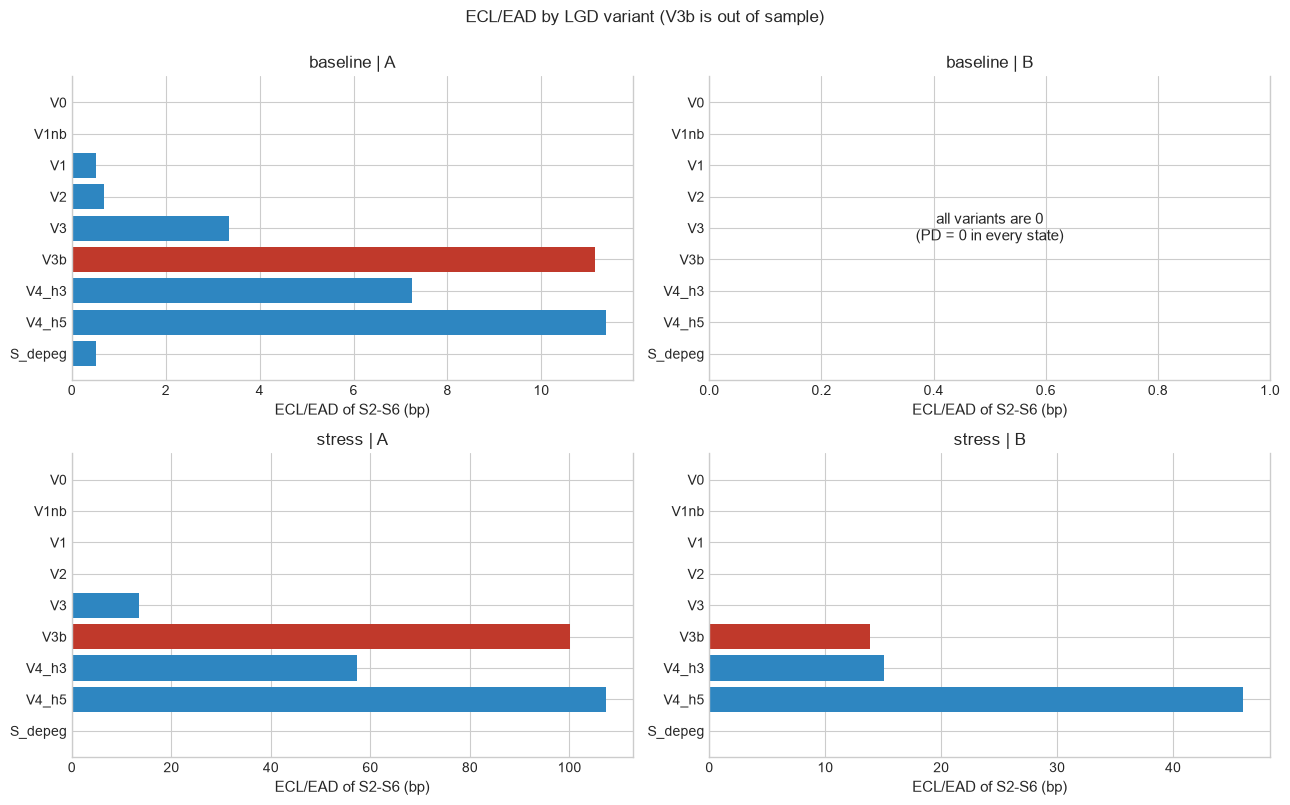

In [12]:
def comparison_matrix(metric: str, line: str, scale: float = 1.0) -> pd.DataFrame:
    """Variants x segments matrix of a metric of one table line."""
    data = {
        segment_name(segment): [scale * variant_tables[v].loc[(segment[0], segment[1], line), metric] for v in VARIANT_ORDER]
        for segment in SEGMENTS
    }
    return pd.DataFrame(data, index=VARIANT_ORDER).rename_axis("variant")


ecl_s2s6 = comparison_matrix("ecl", "S2-S6")
ecl_all = comparison_matrix("ecl", "ALL")
bp_s2s6 = comparison_matrix("ecl_over_ead", "S2-S6", scale=1e4)
bp_all = comparison_matrix("ecl_over_ead", "ALL", scale=1e4)
urp_reference = bp_s2s6 * (365.0 / HORIZON_DAYS)

print("Total ECL of the S2-S6 portfolio (USD):")
display(ecl_s2s6.style.format("{:,.0f}"))
print("\nECL/EAD of the S2-S6 portfolio (bp):")
display(bp_s2s6.style.format("{:.3f}"))
print("\nTotal ECL including the S7-at-valuation line (USD):")
display(ecl_all.style.format("{:,.0f}"))
print("\nECL/EAD including the S7-at-valuation line (bp):")
display(bp_all.style.format("{:.3f}"))
print("\nReference only: implied annualised premium (ECL/EAD of S2-S6) x 365/30, in bp per year:")
display(urp_reference.style.format("{:.2f}"))
print("\nEAD of the S2-S6 portfolio (USD): " + ", ".join(f"{segment_name(s)} = {variant_tables['V1'].loc[(s[0], s[1], 'S2-S6'), 'ead']:,.0f}" for s in SEGMENTS))

fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=False)
for ax, segment in zip(axes.ravel(), SEGMENTS):
    values = bp_s2s6[segment_name(segment)]
    ax.barh(VARIANT_ORDER[::-1], values.to_numpy()[::-1], color=["#c0392b" if v == "V3b" else "#2e86c1" for v in VARIANT_ORDER[::-1]])
    ax.set_title(segment_name(segment))
    ax.set_xlabel("ECL/EAD of S2-S6 (bp)")
    ax.set_xlim(left=0, right=max(float(values.max()) * 1.05, 1.0))
    if float(values.max()) == 0.0:
        ax.text(0.5, 0.5, "all variants are 0\n(PD = 0 in every state)", transform=ax.transAxes, ha="center", va="center", fontsize=11)
fig.suptitle("ECL/EAD by LGD variant (V3b is out of sample)", y=1.0)
plt.tight_layout()
plt.show()

## 9. Economic-sense checklist

The questions the tutor wants answered *before* calibrating the URP. Each check is computed from the tables above; where the answer is "no", the reason is stated.

1. **Stress > baseline?** The PD by state and the ECL/EAD should be higher in the stress scenario for the same profile.
2. **Profile B > profile A?** B is a more volatile collateral (UNI, LINK), so a higher risk is expected. In the baseline, B has no `S7` transition and an empty `S6` row, so its PD is exactly 0 for every state: this is a **rare-event problem of the sample**, not evidence that B is safer. A credibility (Buhlmann-type) or Bayesian smoothing of the B matrix towards the pooled A+B matrix is an option to discuss with the tutor; it is **not implemented** here.
3. **Magnitudes against the observed liquidations.** The expected number of liquidations in the next 30 days implied by $\sum_i n_i \mathrm{PD}_i$ over the valuation cohort is compared with the realised incidence in the calibration window (day-1 cohort) and with the wallets that are already in a liquidation event at $t$. The out-of-time outcomes are *not* used.
4. **Which variants produce a non-zero LGD, and why?** Linked to the break-even table of Section 6.1.

In [13]:
def segment_value(variant: str, line: str, metric: str, segment: tuple[str, str]) -> float:
    """One cell of a variant table."""
    return float(variant_tables[variant].loc[(segment[0], segment[1], line), metric])


def verdict(condition: bool) -> str:
    """Text verdict used in the checklist."""
    return "YES" if condition else "NO"


print("1. Stress > baseline?")
for profile in PROFILES:
    base_pd = markov[("baseline_mar2024", profile)]["pd"].loc[TRANSIENT_STATES, "pd30"]
    stress_pd = markov[("stress_aug2024", profile)]["pd"].loc[TRANSIENT_STATES, "pd30"]
    states_ok = int((stress_pd > base_pd).sum())
    base_ecl, stress_ecl = segment_value("V1", "S2-S6", "ecl_over_ead", ("baseline_mar2024", profile)), segment_value("V1", "S2-S6", "ecl_over_ead", ("stress_aug2024", profile))
    print(f"   profile {profile}: PD30 higher in stress for {states_ok}/5 states -> {verdict(states_ok == 5)};  ECL/EAD V1 S2-S6: baseline {1e4 * base_ecl:.3f} bp, stress {1e4 * stress_ecl:.3f} bp -> {verdict(stress_ecl > base_ecl)}")  # fmt: skip

print("\n2. Profile B > profile A?")
for scenario in SCENARIOS:
    a_pd = markov[(scenario, "A")]["pd"].loc[TRANSIENT_STATES, "pd30"]
    b_pd = markov[(scenario, "B")]["pd"].loc[TRANSIENT_STATES, "pd30"]
    b_empty = [s for s in TRANSIENT_STATES if bool(markov[(scenario, "B")]["row_empty"][s])]
    b_zero = int((b_pd == 0).sum())
    a_ecl, b_ecl = segment_value("V1", "S2-S6", "ecl_over_ead", (scenario, "A")), segment_value("V1", "S2-S6", "ecl_over_ead", (scenario, "B"))
    print(
        f"   {scenario}: PD30(B) > PD30(A) in {int((b_pd > a_pd).sum())}/5 states; states with PD30(B) = 0: {b_zero}; empty rows of B: {b_empty or '-'};"
        f"  ECL/EAD V1 S2-S6: A {1e4 * a_ecl:.3f} bp, B {1e4 * b_ecl:.3f} bp -> {verdict(b_ecl > a_ecl)}"
    )  # fmt: skip
print(
    "   (baseline B: zero S7 transitions in "
    f"{int(markov[('baseline_mar2024', 'B')]['N'].loc[TRANSIENT_STATES].to_numpy().sum()):,} observed transitions; PD = 0 reflects the sample size, not safety.)"
)

print("\n3. Magnitudes against the observed liquidations (no out-of-time data):")
magnitude_rows = []
for segment in SEGMENTS:
    block = variant_tables["V1"].loc[segment[0]].loc[segment[1]]
    at_risk_n = int(block.loc["S2-S6", "n"])
    expected_events = float((valuation.loc[(valuation["scenario"] == segment[0]) & (valuation["profile"] == segment[1]) & ~is_s7, "pd_point"]).sum())
    day1_rows = day1.loc[(day1["scenario"] == segment[0]) & (day1["profile"] == segment[1]) & (day1["state"] != "S7")]
    observed_rate = float((day1_rows["final_state"] == "S7").mean())
    magnitude_rows.append(
        {"segment": segment_name(segment), "valuation S2-S6 wallets": at_risk_n, "expected liquidations in 30d (sum PD)": expected_events,
         "expected rate (%)": 100 * expected_events / max(at_risk_n, 1), "observed rate, day-1 cohort in window (%)": 100 * observed_rate,
         "already in S7 at t (wallets)": int(block.loc["S7", "n"]), "V1 ECL/EAD S2-S6 (bp)": 1e4 * block.loc["S2-S6", "ecl_over_ead"]}
    )  # fmt: skip
display(pd.DataFrame(magnitude_rows).set_index("segment").style.format({"expected liquidations in 30d (sum PD)": "{:.1f}", "expected rate (%)": "{:.2f}", "observed rate, day-1 cohort in window (%)": "{:.2f}", "V1 ECL/EAD S2-S6 (bp)": "{:.3f}"}))

print("\n4. Variants with a non-zero LGD (share of S2-S6 wallets with LGD > 0, and EAD-weighted LGD of S2-S6):")
display(
    pd.concat(
        {
            "share LGD>0 (%)": 100 * pd.DataFrame({v: [variant_tables[v].loc[(s[0], s[1], "S2-S6"), "share_lgd_positive"] for s in SEGMENTS] for v in VARIANT_ORDER}, index=SEGMENT_LABELS),
            "LGD EAD-wtd (%)": 100 * pd.DataFrame({v: [variant_tables[v].loc[(s[0], s[1], "S2-S6"), "lgd_mean"] for s in SEGMENTS] for v in VARIANT_ORDER}, index=SEGMENT_LABELS),
        },
        axis=1,
    ).T.style.format("{:.3f}")
)
non_zero_variants = [v for v in VARIANT_ORDER if (lgd[v][~is_s7] > 0).any()]
zero_variants = [v for v in VARIANT_ORDER if v not in non_zero_variants]
print(f"   variants with LGD > 0 for at least one S2-S6 wallet: {non_zero_variants}")
print(f"   variants with LGD = 0 for every S2-S6 wallet: {zero_variants}")
print("   Break-even link: for a wallet entirely in one asset, V1 > 0 iff ES99 > break-even with bonus (see Section 6.1):")
print(breakeven_check.loc[:, ["scenario", "aave_symbol", "ES99 h=1 shock", "breakeven_with_bonus", "ES99 > break-even (bonus)?", "ES99.5 > break-even (bonus)?"]].to_string(index=False, float_format=lambda x: f"{x:.4f}"))

1. Stress > baseline?
   profile A: PD30 higher in stress for 5/5 states -> YES;  ECL/EAD V1 S2-S6: baseline 0.508 bp, stress 0.000 bp -> NO
   profile B: PD30 higher in stress for 5/5 states -> YES;  ECL/EAD V1 S2-S6: baseline 0.000 bp, stress 0.000 bp -> NO

2. Profile B > profile A?
   baseline_mar2024: PD30(B) > PD30(A) in 0/5 states; states with PD30(B) = 0: 5; empty rows of B: ['S6'];  ECL/EAD V1 S2-S6: A 0.508 bp, B 0.000 bp -> NO
   stress_aug2024: PD30(B) > PD30(A) in 5/5 states; states with PD30(B) = 0: 0; empty rows of B: -;  ECL/EAD V1 S2-S6: A 0.000 bp, B 0.000 bp -> NO
   (baseline B: zero S7 transitions in 8,341 observed transitions; PD = 0 reflects the sample size, not safety.)

3. Magnitudes against the observed liquidations (no out-of-time data):


,valuation S2-S6 wallets,expected liquidations in 30d (sum PD),expected rate (%),"observed rate, day-1 cohort in window (%)",already in S7 at t (wallets),V1 ECL/EAD S2-S6 (bp)
segment,,,,,,
baseline | A,2677,15.1,0.57,0.60,4,0.508
baseline | B,300,0.0,0.00,0.38,1,0.000
stress | A,3857,386.7,10.02,3.59,135,0.000
stress | B,353,51.4,14.56,3.82,11,0.000



4. Variants with a non-zero LGD (share of S2-S6 wallets with LGD > 0, and EAD-weighted LGD of S2-S6):


   variants with LGD > 0 for at least one S2-S6 wallet: ['V1', 'V2', 'V3', 'V3b', 'V4_h3', 'V4_h5', 'S_depeg']
   variants with LGD = 0 for every S2-S6 wallet: ['V0', 'V1nb']
   Break-even link: for a wallet entirely in one asset, V1 > 0 iff ES99 > break-even with bonus (see Section 6.1):
        scenario aave_symbol  ES99 h=1 shock  breakeven_with_bonus  ES99 > break-even (bonus)?  ES99.5 > break-even (bonus)?
baseline_mar2024        WETH          0.1388                0.1285                        True                          True
baseline_mar2024      wstETH          0.1388                0.1414                       False                          True
baseline_mar2024        WBTC          0.1149                0.1810                       False                         False
baseline_mar2024         UNI          0.1497                0.1530                       False                          True
baseline_mar2024        LINK          0.1566                0.2724                   

**Reading of the checklist.** The printed answers are the facts; this is how they read for the discussion.

1. **Stress > baseline holds for the PD, not always for the ECL.** The 30-day PD is higher in stress for every state and both profiles. The ECL/EAD of V1, V2 and S-depeg is *lower* in stress than in the baseline for profile A (zero against about 0.5-0.7 bp; V0 and V1nb are zero in both): the ES 99% of ETH is 13.9% in the baseline window but only 12.1% in the stress window, which puts it below the WETH break-even shock with bonus (12.85%) in stress and above it in the baseline. This is the pending question of `docs/decisions.md` (the stress ES is lower because the two 730-day windows overlap by about 19 months and the baseline window additionally contains March-August 2022, with its sell-off, which the stress window does not); the sign is restored as soon as the shock is raised (V3, V3b, V4).
2. **Profile B > A holds for the PD in stress, not for the ECL.** In stress the PD of B is higher in the five states. But B holds LINK and UNI, whose lower LT leave a break-even margin of 15%-27%, above almost every ES of the grid, so its LGD is zero in most variants and its ECL/EAD is below that of A in V3b and V4. The "riskier collateral" of B shows in the PD, not in the LGD. In the baseline the comparison cannot be made: the B matrix has no `S7` transition and its `S6` row is empty (PD $= 0$ in every state), which is a rare-event problem of the sample, not evidence of safety. A credibility (Buhlmann-type) or Bayesian smoothing of the B matrix towards the pooled A+B matrix is an option to discuss with the tutor; it is **not implemented**.
3. **Magnitudes.** In the baseline the expected 30-day liquidation incidence of the valuation cohort (about 0.6% in profile A) is of the same size as the in-window incidence of the day-1 cohort. In stress it is about 10% against 3.6%: the valuation portfolio of the crash day is concentrated in the risky states (about 39% of the wallets of profile A in `S4`-`S6`), and the in-sample backtest above showed that the stress chain over-predicts by about a factor of two, so the stress PD should be read as an upper figure. The ECL/EAD of the base candidate V1 is about 0.5 bp for the baseline (about 6 bp per year as a reference premium) and zero in stress; the more severe variants give 3-13 bp (V3), 7-57 bp (V4, $h=3$) and 11-107 bp (V4, $h=5$) for profile A.
4. **Which variants give a non-zero LGD.** V0 and V1nb are exactly zero for every wallet in `S2`-`S6` (no loss without the bonus, and V0 cannot be positive when $HF > 1$). V1 is positive only where the ES of the collateral exceeds the break-even with bonus: WETH-type collateral in the baseline (13.9% against 12.85%), which is 72% of the wallets of profile A; wstETH-heavy wallets (break-even 14.1%) and everything in stress stay at zero. V2 adds the gap risk observed in the baseline (HF slightly under 1 when the liquidation arrives); V3, V3b and V4 enlarge the shock and are positive almost everywhere in profile A; S-depeg is almost indistinguishable from V1 because stablecoins are a negligible part of the collateral of these portfolios.
5. **Sensitivity of V2.** The memo of Section 6.4 shows that V2 is fragile: five wallets that were already in `S7` on day 1 (four of them with a Health Factor close to 0: persistent bad debt that was never liquidated) would add tens of basis points in stress if they were counted as entries. They are excluded by construction (they are not transitions), but this has to be discussed before V2 is considered.

## 10. Export of the ECL variants (not for production)

One long table is written to `data/02_interim/ecl_variants_not_for_prod.csv` with columns `scenario, profile, variant, state, n, ead, pd30, lgd_mean, ecl, ecl_over_ead`. `state` takes the values `S2` to `S6`, `S7` (already in a liquidation event at $t$, PD = 1), and the subtotal lines `S2-S6` and `ALL`. In state rows $\text{ecl} = \text{ead} \times \text{pd30} \times \text{lgd\_mean}$ exactly; in `S2-S6` and `ALL` `pd30` and `lgd_mean` are EAD-weighted averages and `ecl` is the exact sum. `variant` is one of `V0, V1nb, V1, V2, V3, V3b, V4_h3, V4_h5, S_depeg`; **`V3b` is out of sample** (99.9% on a 730-day window) and **every variant is exploratory**.

**Checks before writing:** no missing identifiers, `0 <= lgd_mean <= 1`, `0 <= ecl <= ead`, `n` adds up to the valuation cohort of each segment, the subtotals equal the sum of their states. **After writing:** the file is read back, compared exactly with the table in memory, and the V1 totals are recomputed from the file and from the wallet-level arrays.

In [14]:
EXPORT_COLUMNS = ["scenario", "profile", "variant", "state", "n", "ead", "pd30", "lgd_mean", "ecl", "ecl_over_ead"]
ROUND_TRIP_TOLERANCE = 1e-12


def build_export_table() -> pd.DataFrame:
    """Stack the variant tables in long format (rows for states without wallets keep n = 0 and empty ratios)."""
    frames = []
    for variant in VARIANT_ORDER:
        frame = variant_tables[variant].reset_index().assign(variant=variant)
        frames.append(frame)
    long = pd.concat(frames, ignore_index=True)
    long["state"] = pd.Categorical(long["state"], categories=LINE_ORDER, ordered=True)
    long["variant"] = pd.Categorical(long["variant"], categories=VARIANT_ORDER, ordered=True)
    long = long.sort_values(["scenario", "profile", "variant", "state"], kind="mergesort").reset_index(drop=True)
    long["state"], long["variant"] = long["state"].astype(str), long["variant"].astype(str)
    return long[EXPORT_COLUMNS]


def validate_export_table(table: pd.DataFrame) -> None:
    """Consistency checks of the export table before writing."""
    assert list(table.columns) == EXPORT_COLUMNS
    assert table[["scenario", "profile", "variant", "state", "n", "ead", "ecl"]].notna().all().all()
    assert not table.duplicated(["scenario", "profile", "variant", "state"]).any()
    assert set(table["variant"]) == set(VARIANT_ORDER) and set(table["state"]) == set(LINE_ORDER)
    populated = table["n"] > 0
    assert table.loc[populated, ["pd30", "lgd_mean", "ecl_over_ead"]].notna().all().all(), "A populated line has an empty ratio."
    assert table.loc[populated, "lgd_mean"].between(0, 1).all(), "lgd_mean outside [0, 1]."
    assert table.loc[populated, "pd30"].between(0, 1).all() and table.loc[populated, "ecl_over_ead"].between(0, 1).all()
    assert (table["ecl"] >= -1e-9).all() and (table["ecl"] <= table["ead"] + 1e-6).all(), "ecl outside [0, ead]."
    for (scenario, profile, variant), block in table.groupby(["scenario", "profile", "variant"]):
        by_state = block.set_index("state")
        n_cohort = int(((valuation["scenario"] == scenario) & (valuation["profile"] == profile)).sum())
        assert by_state.loc[TRANSIENT_STATES + ["S7"], "n"].sum() == n_cohort == by_state.loc["ALL", "n"], "n does not add up to the cohort."
        assert by_state.loc["S2-S6", "n"] == by_state.loc[TRANSIENT_STATES, "n"].sum()
        assert np.isclose(by_state.loc["S2-S6", "ecl"], by_state.loc[TRANSIENT_STATES, "ecl"].sum(), rtol=1e-12, atol=1e-9)
        assert np.isclose(by_state.loc["ALL", "ecl"], by_state.loc[TRANSIENT_STATES + ["S7"], "ecl"].sum(), rtol=1e-12, atol=1e-9)
        assert np.isclose(by_state.loc["ALL", "ead"], by_state.loc[TRANSIENT_STATES + ["S7"], "ead"].sum(), rtol=1e-12, atol=1e-6)


def write_csv_exact(table: pd.DataFrame, output_path: Path) -> pd.DataFrame:
    """Write a table to CSV and return it read back with exact float parsing."""
    output_path.parent.mkdir(parents=True, exist_ok=True)
    try:
        table.to_csv(output_path, index=False)
        return pd.read_csv(output_path, float_precision="round_trip")
    except OSError as exc:
        raise OSError(f"Failed to write or reload {output_path.resolve()}: {exc}") from exc


export_table = build_export_table()
validate_export_table(export_table)
export_reloaded = write_csv_exact(export_table, ECL_EXPORT_PATH)

# --- round trip: file versus table in memory -----------------------------------------------------------
pd.testing.assert_frame_equal(export_reloaded, export_table, check_dtype=False, rtol=0, atol=0)
validate_export_table(export_reloaded)

# --- round trip: V1 and V2 totals recomputed from the file and from the wallet-level arrays -----------------
max_gap = 0.0
for variant in VARIANT_ORDER:
    for segment in SEGMENTS:
        seg_mask = ((valuation["scenario"] == segment[0]) & (valuation["profile"] == segment[1])).to_numpy()
        from_wallets = float(wallet_ecl[variant][seg_mask].sum())
        from_file = float(export_reloaded.loc[
            (export_reloaded["scenario"] == segment[0]) & (export_reloaded["profile"] == segment[1])
            & (export_reloaded["variant"] == variant) & (export_reloaded["state"] == "ALL"), "ecl"].iloc[0])  # fmt: skip
        gap = abs(from_wallets - from_file) / max(1.0, abs(from_wallets))
        max_gap = max(max_gap, gap)
        assert gap <= 1e-9, f"{variant} {segment}: ECL recomputed from wallets differs from the file by {gap:.2e}."

print("Export written (manual notebook export, NOT for production):")
print(f"  {ECL_EXPORT_PATH.resolve()}  ({len(export_table)} rows = {len(SEGMENTS)} segments x {len(VARIANT_ORDER)} variants x {len(LINE_ORDER)} lines)")
print(f"  round trip OK: file equals the in-memory table exactly; max relative gap of ECL totals vs wallet-level = {max_gap:.2e}")
display(export_reloaded.loc[export_reloaded["variant"].isin(["V1"]) & export_reloaded["state"].isin(["S2-S6", "S7", "ALL"])].round(8))

Export written (manual notebook export, NOT for production):
  C:\Users\facun\Repos\Tesina\data\02_interim\ecl_variants_not_for_prod.csv  (288 rows = 4 segments x 9 variants x 8 lines)
  round trip OK: file equals the in-memory table exactly; max relative gap of ECL totals vs wallet-level = 1.88e-16


,scenario,profile,variant,state,n,ead,pd30,lgd_mean,ecl,ecl_over_ead
21,baseline_mar2024,A,V1,S2-S6,2677,9.007873e+08,0.009940,0.006269,45785.095149,0.000051
22,baseline_mar2024,A,V1,S7,4,2.434916e+04,1.000000,0.006905,168.128147,0.006905
23,baseline_mar2024,A,V1,ALL,2681,9.008117e+08,0.009967,0.006269,45953.223295,0.000051
93,baseline_mar2024,B,V1,S2-S6,300,2.416963e+07,0.000000,0.000000,0.000000,0.000000
94,baseline_mar2024,B,V1,S7,1,9.459863e+02,1.000000,0.198556,187.831593,0.198556
95,baseline_mar2024,B,V1,ALL,301,2.417058e+07,0.000039,0.000008,187.831593,0.000008
165,stress_aug2024,A,V1,S2-S6,3857,1.213342e+09,0.132359,0.000000,0.000000,0.000000
166,stress_aug2024,A,V1,S7,135,8.771790e+06,1.000000,0.000351,3076.708364,0.000351
167,stress_aug2024,A,V1,ALL,3992,1.222114e+09,0.138587,0.000003,3076.708364,0.000003
237,stress_aug2024,B,V1,S2-S6,353,2.805038e+07,0.187186,0.000000,0.000000,0.000000
